# Лабораторная работа № 3

## Кластеризация

## 1. Введение

### Цель работы

Изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации полученных результатов.

### Задачи работы

1. Загрузить и исследовать набор данных, определить его размерность, типы признаков, наличие пропусков и дубликатов.
2. Изучить распределения признаков, оценить их вариативность и выявить выбросы.
3. Подготовить данные к кластеризации: выбрать признаки, обработать специальные значения, закодировать категориальные переменные и стандартизировать числовые.
4. Исследовать структуру данных с помощью матрицы диаграмм рассеивания.
5. Реализовать два алгоритма кластеризации и подобрать количество кластеров.
6. Рассчитать внутренние и внешние метрики качества, исследовать компактность и расстояния между кластерами.
7. Исследовать влияние количества кластеров на результат, проверить устойчивость разбиения.
8. Визуализировать кластеры, проанализировать их характеристики и сравнить результаты двух методов.

В работе используется датасет **Bank Marketing**. Кластеризация выполняется без использования целевой переменной `y`. Она будет отделена от признаков и применена только на заключительном этапе для внешней оценки полученных групп.

## 2. Выбор и исследование датасета

### 2.1. Источник и описание данных

Для лабораторной работы выбран набор данных **Bank Marketing** из репозитория UCI Machine Learning Repository. Он содержит сведения о клиентах банка, их демографических и финансовых характеристиках, а также информацию о взаимодействии с банком в рамках маркетинговых кампаний.

Источник данных: [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).

Используется именно набор **Bank Marketing**, а не отдельный датасет с названием Bank Customer Segmentation. Он подходит для данной работы, поскольку содержит демографические, финансовые и поведенческие характеристики клиентов, а также историю взаимодействия с банком.

В исходном файле `bank.csv` содержится **4521 наблюдение и 17 столбцов**. Каждая строка соответствует одному клиенту.

Целевая переменная `y` показывает, оформил ли клиент срочный банковский депозит (`yes` / `no`). Поскольку задача лабораторной — кластеризация без учителя, `y` не будет входить в матрицу признаков и не будет участвовать в обучении алгоритмов. Она сохранится отдельно для дополнительной внешней оценки.

### 2.2. Описание признаков

| Признак | Описание |
|---|---|
| `age` | Возраст клиента, лет |
| `job` | Профессия клиента |
| `marital` | Семейное положение |
| `education` | Уровень образования |
| `default` | Наличие просрочки по кредиту |
| `balance` | Баланс банковского счёта |
| `housing` | Наличие жилищного кредита |
| `loan` | Наличие потребительского кредита |
| `contact` | Тип связи с клиентом |
| `day`, `month` | День и месяц последнего контакта |
| `duration` | Продолжительность последнего контакта, секунд |
| `campaign` | Количество контактов в текущей кампании |
| `pdays` | Количество дней после предыдущего контакта; `-1` означает отсутствие предыдущего контакта |
| `previous` | Количество контактов до текущей кампании |
| `poutcome` | Результат предыдущей маркетинговой кампании |
| `y` | Факт оформления срочного депозита (`yes` / `no`) |

Для кластеризации особенно важны демографические и финансовые характеристики клиента, а также история взаимодействия с банком.

### 2.3. Загрузка датасета

Файл `bank.csv` должен находиться в одной папке с ноутбуком. В исходном файле значения разделены точкой с запятой, поэтому при чтении используется параметр `sep=";"`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    pairwise_distances
)

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from itertools import combinations

# Настройки отображения таблиц и графиков
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42

# Проверяем наличие файла рядом с ноутбуком
DATA_PATH = Path("bank.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Файл bank.csv не найден. Помести его в одну папку с ноутбуком."
    )

# Загружаем данные
# В исходном файле Bank Marketing используется разделитель ';'
df = pd.read_csv(DATA_PATH, sep=";")

print(f"Количество объектов: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

display(df.head())

Количество объектов: 4521
Количество столбцов: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### 2.4. Первичная проверка качества данных

На этом этапе проверим типы переменных, количество пропущенных значений и полных дубликатов. Отдельно обратим внимание на значения `unknown`: они встречаются в категориальных столбцах и обозначают неизвестную или неуказанную категорию, но не являются пропусками `NaN`.

In [2]:
# Информация о типах и количестве непустых значений
print("Информация о датасете:")
df.info()

# Количество пропусков в каждом столбце
missing_summary = df.isna().sum().to_frame(name="Количество пропусков")
display(missing_summary)

# Проверка полных дубликатов
duplicates_count = df.duplicated().sum()
print(f"Количество полных дубликатов: {duplicates_count}")

# Проверяем значения категорий unknown
categorical_columns_all = df.select_dtypes(exclude="number").columns.tolist()
unknown_summary = pd.Series({
    column: int((df[column] == "unknown").sum())
    for column in categorical_columns_all
}, name="Количество значений unknown")
display(unknown_summary.to_frame())

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


,Количество пропусков
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Количество полных дубликатов: 0


,Количество значений unknown
job,38
marital,0
education,187
default,0
housing,0
loan,0
contact,1324
month,0
poutcome,3705
y,0


#### Вывод по первичной проверке

Датасет содержит 4521 объект и 17 столбцов. В нём представлены числовые и категориальные признаки. Пропущенные значения `NaN` и полные дубликаты отсутствуют.

В некоторых категориальных переменных встречается значение `unknown`. Оно сохраняется как отдельная категория: заменять его на пропуск или удалять соответствующие строки не требуется. В дальнейшем категориальные значения будут преобразованы в бинарные признаки с помощью One-Hot Encoding.

### 2.5. Анализ числовых признаков

Рассчитаем описательные статистики числовых переменных и построим гистограммы. Гистограммы позволяют оценить форму распределения, асимметрию и возможное отклонение от нормального распределения.

,count,mean,std,min,25%,50%,75%,max
age (возраст клиента),4521.0,41.17,10.58,19.0,33.0,39.0,49.0,87.0
balance (баланс банковского счёта),4521.0,1422.66,3009.64,-3313.0,69.0,444.0,1480.0,71188.0
day (день последнего контакта),4521.0,15.92,8.25,1.0,9.0,16.0,21.0,31.0
"duration (продолжительность контакта, сек.)",4521.0,263.96,259.86,4.0,104.0,185.0,329.0,3025.0
campaign (контакты в текущей кампании),4521.0,2.79,3.11,1.0,1.0,2.0,3.0,50.0
pdays (дней с предыдущего контакта),4521.0,39.77,100.12,-1.0,-1.0,-1.0,-1.0,871.0
previous (контакты до текущей кампании),4521.0,0.54,1.69,0.0,0.0,0.0,0.0,25.0


,Коэффициент асимметрии
age (возраст клиента),0.700
balance (баланс банковского счёта),6.596
day (день последнего контакта),0.095
"duration (продолжительность контакта, сек.)",2.772
campaign (контакты в текущей кампании),4.744
pdays (только предыдущие контакты),0.902
previous (контакты до текущей кампании),5.875


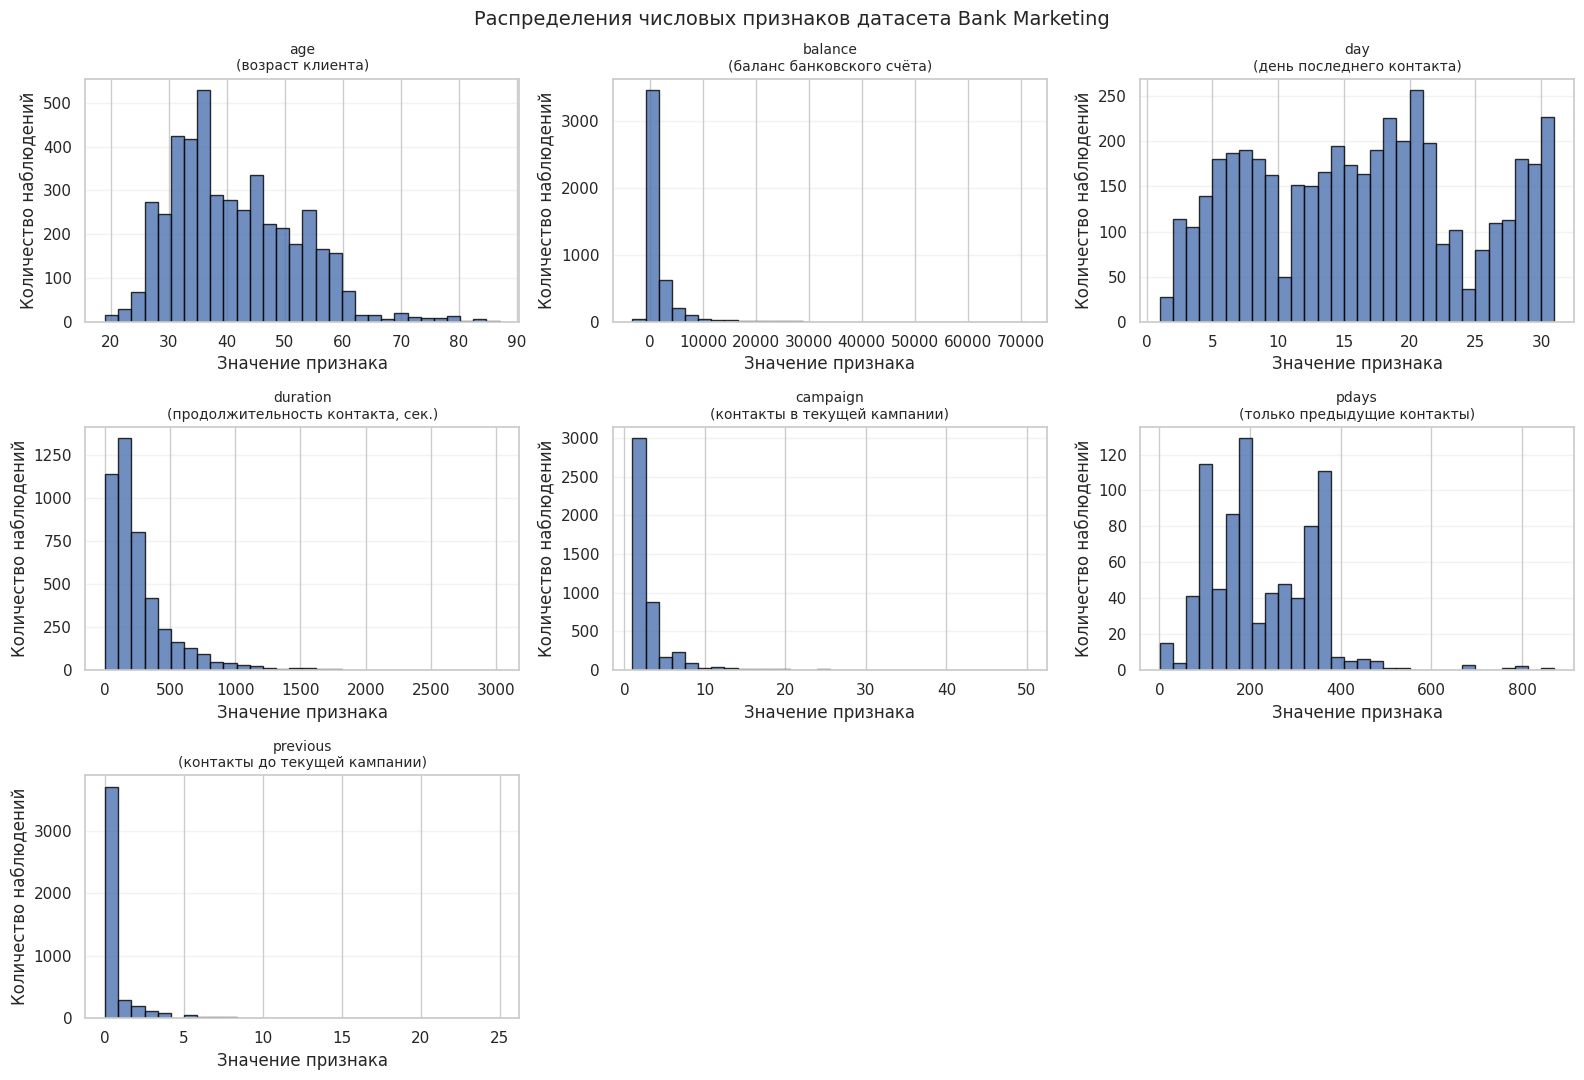

Клиентов без предыдущего контакта (pdays = -1): 3705 (81.95%)


In [3]:
# Названия числовых признаков и их пояснения
numeric_descriptions = {
    "age": "возраст клиента",
    "balance": "баланс банковского счёта",
    "day": "день последнего контакта",
    "duration": "продолжительность контакта, сек.",
    "campaign": "контакты в текущей кампании",
    "pdays": "дней с предыдущего контакта",
    "previous": "контакты до текущей кампании"
}

# Выбираем числовые столбцы автоматически
numeric_columns_all = df.select_dtypes(include="number").columns.tolist()

# Рассчитываем описательные статистики
numeric_summary = df[numeric_columns_all].describe().T.round(2)
numeric_summary.index = [
    f"{column} ({numeric_descriptions[column]})"
    for column in numeric_columns_all
]
display(numeric_summary)

# Рассчитываем асимметрию распределений
skew_values = df[numeric_columns_all].skew()

# Для pdays исключаем специальное значение -1, как и на гистограмме.
skew_values["pdays"] = df.loc[df["pdays"] != -1, "pdays"].skew()

skew_summary = skew_values.to_frame(
    name="Коэффициент асимметрии"
).round(3)
skew_summary.index = [
    "pdays (только предыдущие контакты)"
    if column == "pdays"
    else f"{column} ({numeric_descriptions[column]})"
    for column in numeric_columns_all
]
display(skew_summary)

# Строим гистограммы распределений числовых признаков
fig, axes = plt.subplots(3, 3, figsize=(16, 11))

for ax, column in zip(axes.flat, numeric_columns_all):
    # Значение -1 в pdays означает отсутствие предыдущего контакта.
    # Для гистограммы дней рассматриваем только клиентов с историей контактов.
    if column == "pdays":
        values = df.loc[df[column] != -1, column]
        title = "pdays\n(только предыдущие контакты)"
    else:
        values = df[column]
        title = f"{column}\n({numeric_descriptions[column]})"

    ax.hist(values, bins=30, edgecolor="black", alpha=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Значение признака")
    ax.set_ylabel("Количество наблюдений")
    ax.grid(axis="y", alpha=0.25)

# Скрываем лишние области графика
for ax in axes.flat[len(numeric_columns_all):]:
    ax.set_visible(False)

fig.suptitle(
    "Распределения числовых признаков датасета Bank Marketing",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Отдельно показываем долю клиентов без предыдущего контакта
no_previous_contact = int((df["pdays"] == -1).sum())
no_previous_contact_share = (df["pdays"] == -1).mean() * 100
print(
    f"Клиентов без предыдущего контакта (pdays = -1): "
    f"{no_previous_contact} ({no_previous_contact_share:.2f}%)"
)

#### Вывод по распределению числовых признаков

Распределения числовых переменных неоднородны. Возраст имеет умеренную правостороннюю асимметрию. Баланс счёта, продолжительность контакта, количество контактов и число предыдущих контактов имеют выраженную правостороннюю асимметрию.

Распределение `pdays` имеет особенность: большое количество значений равно `-1`, поскольку этот код обозначает отсутствие предыдущего контакта. Поэтому его нельзя интерпретировать как обычное отрицательное количество дней. На гистограмме и при расчёте коэффициента асимметрии показаны только реальные значения количества дней, а доля клиентов с `pdays = -1` выводится отдельно.

Большинство числовых признаков не имеет нормального распределения. Это не запрещает применение K-means и иерархической кластеризации, однако делает особенно важными обработку масштаба и анализ выбросов.

### 2.6. Анализ категориальных признаков

Для категориальных переменных изучим частоты встречаемости значений. Это позволит увидеть преобладающие категории и оценить, насколько разнообразны признаки.

,Количество категорий,Наиболее частая категория,"Доля наиболее частой категории, %"
job,12,management,21.43
marital,3,married,61.87
education,4,secondary,51.01
default,2,no,98.32
housing,2,yes,56.60
loan,2,no,84.72
contact,3,cellular,64.06
month,12,may,30.92
poutcome,4,unknown,81.95


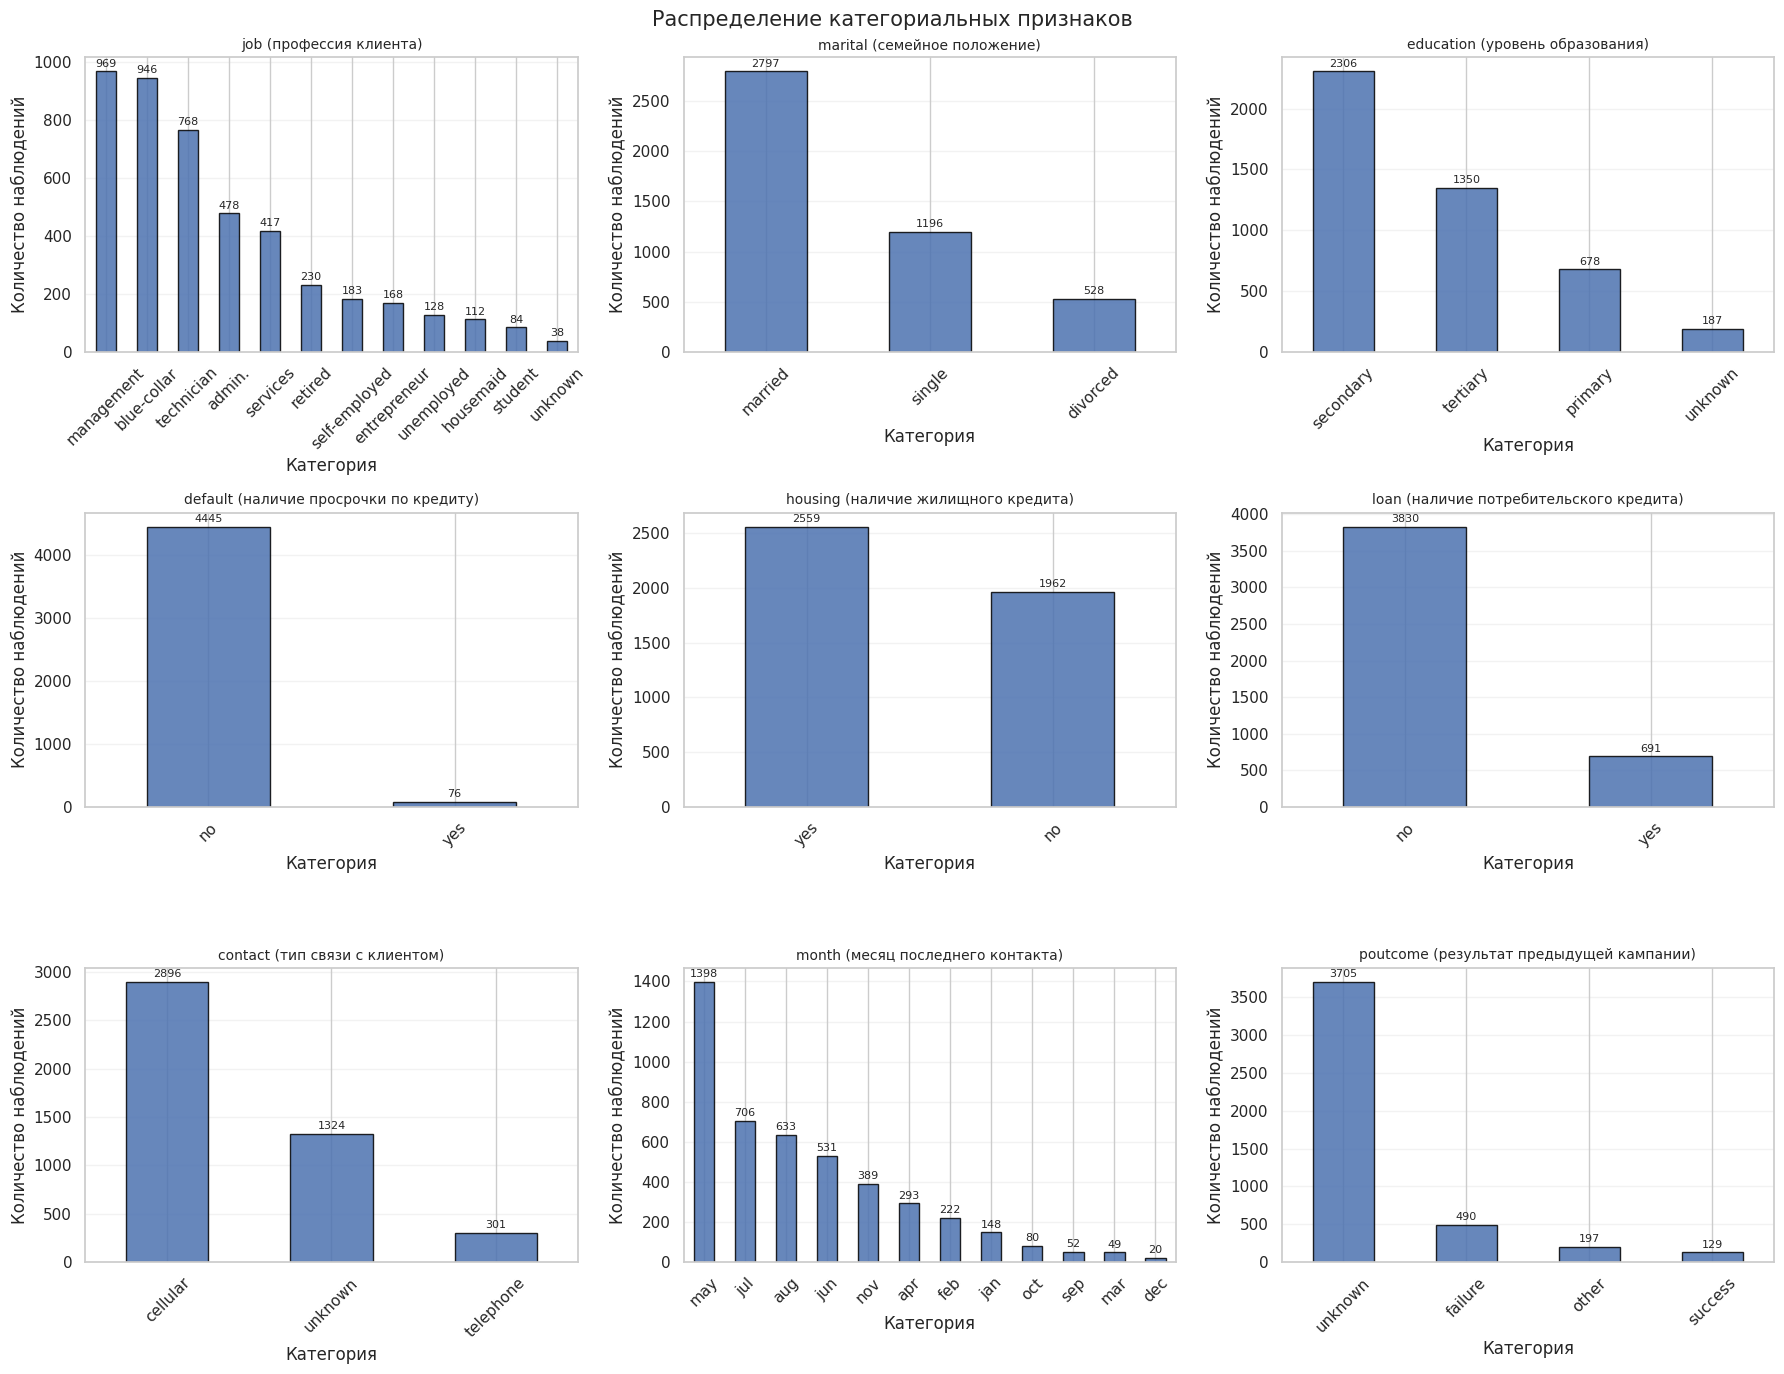

In [4]:
# Названия категориальных признаков и их пояснения
categorical_descriptions = {
    "job": "профессия клиента",
    "marital": "семейное положение",
    "education": "уровень образования",
    "default": "наличие просрочки по кредиту",
    "housing": "наличие жилищного кредита",
    "loan": "наличие потребительского кредита",
    "contact": "тип связи с клиентом",
    "month": "месяц последнего контакта",
    "poutcome": "результат предыдущей кампании"
}

categorical_columns = list(categorical_descriptions.keys())

# Формируем сводную таблицу категориальных признаков
categorical_summary = pd.DataFrame(index=categorical_columns)
categorical_summary["Количество категорий"] = [
    df[column].nunique(dropna=False)
    for column in categorical_columns
]
categorical_summary["Наиболее частая категория"] = [
    df[column].value_counts(dropna=False).index[0]
    for column in categorical_columns
]
categorical_summary["Доля наиболее частой категории, %"] = [
    df[column].value_counts(normalize=True, dropna=False).iloc[0] * 100
    for column in categorical_columns
]
display(categorical_summary.round(2))

# Строим диаграммы распределения категорий
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, column in zip(axes.flat, categorical_columns):
    counts = df[column].value_counts(dropna=False)
    counts.plot(
        kind="bar",
        ax=ax,
        edgecolor="black",
        alpha=0.85
    )
    ax.set_title(
        f"{column} ({categorical_descriptions[column]})",
        fontsize=10
    )
    ax.set_xlabel("Категория")
    ax.set_ylabel("Количество наблюдений")
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(axis="y", alpha=0.25)

    # Подписываем столбцы, поскольку число категорий невелико
    if len(counts) <= 12:
        for container in ax.containers:
            ax.bar_label(container, fontsize=8, padding=2)

fig.suptitle(
    "Распределение категориальных признаков",
    fontsize=15
)
plt.tight_layout()
plt.show()

### 2.7. Оценка информационной значимости признаков

В задаче кластеризации нет целевой метки, по которой можно напрямую рассчитать важность признаков как в задаче классификации. Поэтому на данном этапе используется предварительная оценка вариативности признаков:

- для числовых признаков рассматриваются дисперсия, стандартное отклонение и количество уникальных значений;
- для категориальных признаков рассчитывается нормированная энтропия Шеннона. Она показывает разнообразие категорий: значение ближе к 1 соответствует более равномерному распределению, а значение ближе к 0 — преобладанию одной категории.

Эта оценка не является прогнозной важностью признака. Она помогает обнаружить переменные с низкой вариативностью и оценить, насколько полезным может быть их включение в анализ.

,Количество уникальных значений,Дисперсия,Стандартное отклонение
age,67,111.856,10.576
balance,2353,9057921.749,3009.638
day,31,68.024,8.248
duration,875,67525.470,259.857
campaign,32,9.671,3.110
pdays,292,10024.240,100.121
previous,24,2.868,1.694


,Признак,Количество категорий,Энтропия,Нормированная энтропия
4,housing,2,0.987,0.987
0,job,12,3.068,0.856
1,marital,3,1.298,0.819
7,month,12,2.920,0.814
2,education,4,1.617,0.808
6,contact,3,1.191,0.751
5,loan,2,0.617,0.617
8,poutcome,4,0.926,0.463
3,default,2,0.123,0.123


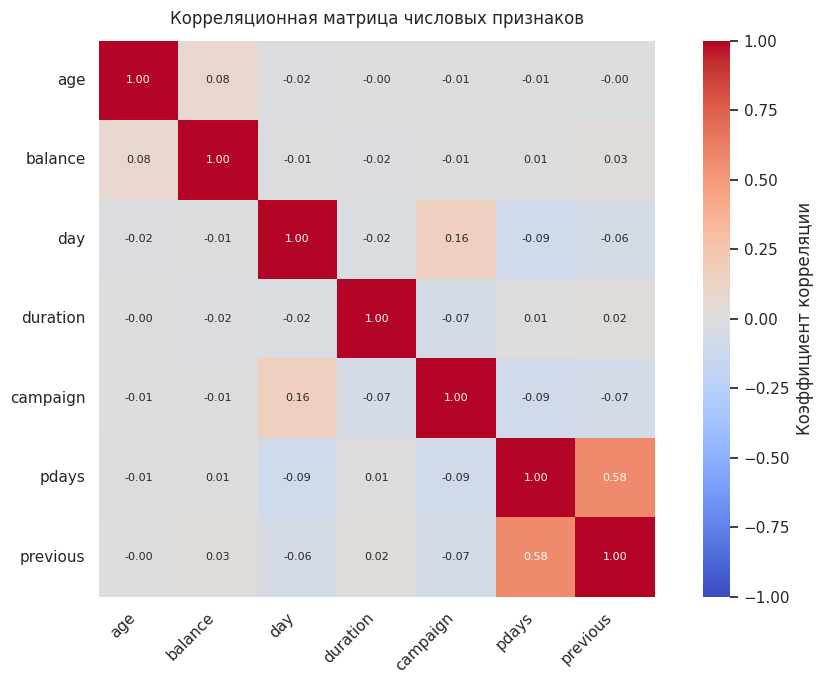

Корреляция pdays и previous среди клиентов с предыдущим контактом: -0.041
Количество таких клиентов: 816


In [5]:
# Вариативность числовых признаков
numeric_information = pd.DataFrame({
    "Количество уникальных значений": df[numeric_columns_all].nunique(),
    "Дисперсия": df[numeric_columns_all].var(),
    "Стандартное отклонение": df[numeric_columns_all].std()
}).round(3)

display(numeric_information)

# Нормированная энтропия категориальных признаков
entropy_rows = []

for column in categorical_columns:
    probabilities = df[column].value_counts(normalize=True)
    entropy = -(probabilities * np.log2(probabilities)).sum()
    number_of_categories = df[column].nunique()
    max_entropy = np.log2(number_of_categories) if number_of_categories > 1 else 0
    normalized_entropy = entropy / max_entropy if max_entropy > 0 else 0

    entropy_rows.append({
        "Признак": column,
        "Количество категорий": number_of_categories,
        "Энтропия": entropy,
        "Нормированная энтропия": normalized_entropy
    })

entropy_summary = (
    pd.DataFrame(entropy_rows)
    .sort_values("Нормированная энтропия", ascending=False)
    .round(3)
)

display(entropy_summary)

# Корреляционная матрица числовых признаков
correlation_matrix = df[numeric_columns_all].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0,
    square=True,
    annot_kws={"size": 8},
    cbar_kws={"label": "Коэффициент корреляции"},
    ax=ax
)
ax.set_title("Корреляционная матрица числовых признаков", pad=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.grid(False)
plt.tight_layout()
plt.show()

# Проверяем связь pdays и previous отдельно среди клиентов с предыдущим контактом
history_clients = df["pdays"] != -1
history_correlation = df.loc[
    history_clients, ["pdays", "previous"]
].corr().iloc[0, 1]
print(
    "Корреляция pdays и previous среди клиентов с предыдущим контактом:",
    round(history_correlation, 3)
)
print("Количество таких клиентов:", int(history_clients.sum()))

#### Вывод по информационной значимости

Для числовых признаков рассчитаны дисперсия, стандартное отклонение и число уникальных значений. Дисперсия зависит от единиц измерения, поэтому её нельзя напрямую трактовать как важность признака. Для сравнения масштабы числовых переменных далее будут приведены к стандартному виду.

Среди категориальных признаков, выбранных для кластеризации, наиболее разнообразны `housing`, `job`, `marital` и `education`. Однако вариативность сама по себе не доказывает вклад признака в разделение на кластеры. Поэтому показатели этого раздела рассматриваются как предварительная оценка информативности, а не как автоматический критерий отбора. Состав признаков в разделе 3.1 выбран с учётом их предметного смысла; например, маловариативный `default` сохранён как характеристика кредитного риска, а `y`, `duration`, `day` и `month` исключены по указанным там причинам. У признака `default` низкая нормированная энтропия: большинство клиентов не имеют указанной просрочки. Признак всё равно сохраняется, поскольку он имеет самостоятельный финансовый смысл. `month` также обладает высокой вариативностью, но исключается из кластеризации как календарный параметр контакта.

На корреляционной матрице связь `pdays` и `previous` для всех клиентов составляет около 0,58. Однако она во многом связана с особыми кодами отсутствия предыдущего контакта (`pdays = -1` и `previous = 0`). Если рассматривать только 816 клиентов, у которых предыдущий контакт был, корреляция близка к нулю (около -0,041). Поэтому значение 0,58 нельзя трактовать как сильную связь между количеством дней и числом контактов внутри этой группы.

### 2.8. Выявление и анализ выбросов

Для предварительного выявления выбросов используем правило межквартильного размаха (IQR):

\[
IQR = Q_3 - Q_1
\]

Границы потенциальных выбросов:

\[
Q_1 - 1.5 \cdot IQR, \qquad Q_3 + 1.5 \cdot IQR
\]

Значения за этими границами помечаются как потенциальные выбросы. При этом статистический выброс не обязательно является ошибкой: например, большой баланс или большое количество предыдущих контактов могут быть реальными характеристиками клиента.

,База расчёта,Объектов в расчёте,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Потенциальные выбросы,"Доля в группе, %"
Признак,,,,,,,,,
age,Все клиенты,4521,33.0,49.0,16.0,9.0,73.0,38,0.84
balance,Все клиенты,4521,69.0,1480.0,1411.0,-2047.5,3596.5,506,11.19
day,Все клиенты,4521,9.0,21.0,12.0,-9.0,39.0,0,0.00
duration,Все клиенты,4521,104.0,329.0,225.0,-233.5,666.5,330,7.30
campaign,Все клиенты,4521,1.0,3.0,2.0,-2.0,6.0,318,7.03
pdays,Только pdays != -1,816,136.0,330.0,194.0,-155.0,621.0,7,0.86
previous,Только previous > 0,816,1.0,4.0,3.0,-3.5,8.5,34,4.17


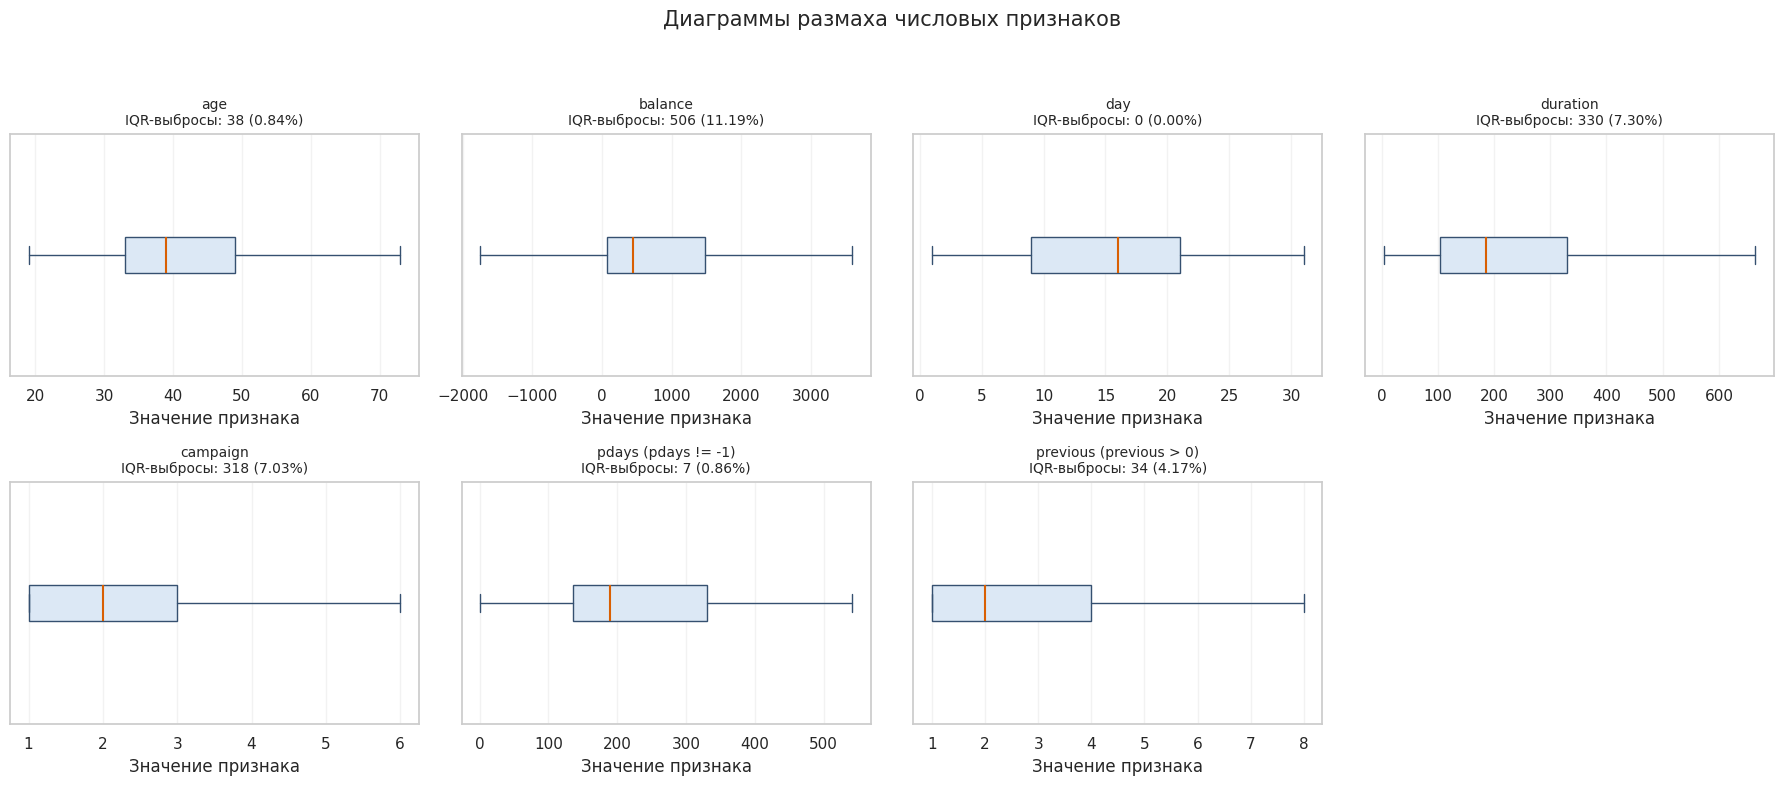

Количество клиентов с pdays = -1: 3705
Доля клиентов с pdays = -1, %: 81.95
Количество клиентов с previous = 0: 3705


In [6]:
outlier_rows = []
outlier_series = {}
outlier_info = {}

for column in numeric_columns_all:
    # Значения -1 в pdays и 0 в previous означают отсутствие предыдущего контакта.
    # Исключаем их из IQR-расчёта, чтобы не считать их ложными выбросами.
    if column == "pdays":
        series = df.loc[df[column] != -1, column]
        calculation_basis = "Только pdays != -1"
    elif column == "previous":
        series = df.loc[df[column] > 0, column]
        calculation_basis = "Только previous > 0"
    else:
        series = df[column]
        calculation_basis = "Все клиенты"

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (series < lower_bound) | (series > upper_bound)
    outlier_count = int(outlier_mask.sum())
    outlier_share = outlier_mask.mean() * 100 if len(series) else 0

    outlier_series[column] = series
    outlier_info[column] = (outlier_count, outlier_share)
    outlier_rows.append({
        "Признак": column,
        "База расчёта": calculation_basis,
        "Объектов в расчёте": len(series),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Нижняя граница": lower_bound,
        "Верхняя граница": upper_bound,
        "Потенциальные выбросы": outlier_count,
        "Доля в группе, %": outlier_share
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("Признак").round(2)
display(outlier_summary)

# Скрываем отдельные маркеры выбросов, чтобы не перегружать график.
# Их количество и доля остаются в таблице и заголовках подграфиков.
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, column in zip(axes.flat, numeric_columns_all):
    values = outlier_series[column]
    outlier_count, outlier_share = outlier_info[column]
    ax.boxplot(
        values,
        vert=False,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#dce8f5", "edgecolor": "#355070"},
        medianprops={"color": "#d95f02", "linewidth": 1.5},
        whiskerprops={"color": "#355070"},
        capprops={"color": "#355070"}
    )
    plot_title = column
    if column == "pdays":
        plot_title = "pdays (pdays != -1)"
    elif column == "previous":
        plot_title = "previous (previous > 0)"
    ax.set_title(
        f"{plot_title}\nIQR-выбросы: {outlier_count} ({outlier_share:.2f}%)",
        fontsize=10
    )
    ax.set_xlabel("Значение признака")
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.25)

for ax in axes.flat[len(numeric_columns_all):]:
    ax.set_visible(False)

fig.suptitle(
    "Диаграммы размаха числовых признаков",
    fontsize=15
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

print("Количество клиентов с pdays = -1:", int((df["pdays"] == -1).sum()))
print("Доля клиентов с pdays = -1, %:", round((df["pdays"] == -1).mean() * 100, 2))
print("Количество клиентов с previous = 0:", int((df["previous"] == 0).sum()))

#### Вывод по выбросам

Правило IQR выявляет потенциальные выбросы в нескольких числовых переменных. Наиболее заметны значения `balance`, `campaign`, `duration`, `pdays` и `previous`.

При интерпретации необходимо учитывать структуру данных:

- значения `pdays = -1` — специальный код отсутствия предыдущего контакта, а не ошибка;
- нулевые значения `previous` означают отсутствие контактов до текущей кампании;
- большие значения баланса и количества контактов могут быть реальными наблюдениями;
- возрастные значения за верхней границей IQR не удаляются, поскольку они могут соответствовать реальному возрасту клиента.

Удалять целые строки не будем. Для отдельных сильно асимметричных числовых признаков далее применим ограничение крайних 1% и 99% значений (winsorization). Это уменьшит влияние наиболее экстремальных значений на евклидовы расстояния, сохранив все 4521 наблюдение. Не каждый объект, отмеченный правилом IQR, удаляется или ограничивается: часть таких значений является допустимыми характеристиками клиентов. Например, реальные значения возраста сохраняются. Поэтому корректнее говорить об анализе и смягчении влияния выбросов, а не об их полном отсутствии.

Дополнительно: для `pdays` IQR рассчитывается только среди клиентов с `pdays != -1`, а для `previous` — среди клиентов с `previous > 0`. Так специальные значения отсутствия предыдущего контакта не превращаются в ложные выбросы. Отдельные точки-выбросы на диаграммах скрыты для читаемости, а их количество и доля показаны в таблице.

### 2.9. Проверка пригодности данных для кластеризации

Кластеризация применяется для поиска естественных групп объектов без заранее заданных меток. В наборе данных присутствует переменная `y`, однако она не будет использоваться при формировании кластеров.

Датасет подходит для исследования: он содержит осмысленные демографические, финансовые и поведенческие характеристики клиентов, пропуски и полные дубликаты отсутствуют. Потенциальные выбросы выявлены и будут обработаны без удаления наблюдений.

Переменная `y` взята из исходного датасета Bank Marketing и показывает, оформил ли клиент срочный депозит после маркетингового контакта. Поскольку в ТЗ предусмотрена внешняя оценка при наличии исходной разметки, `y` сохраняется отдельно и используется только после построения кластеров.

,Количество клиентов,"Доля, %"
y,,
no,4000,88.48
yes,521,11.52


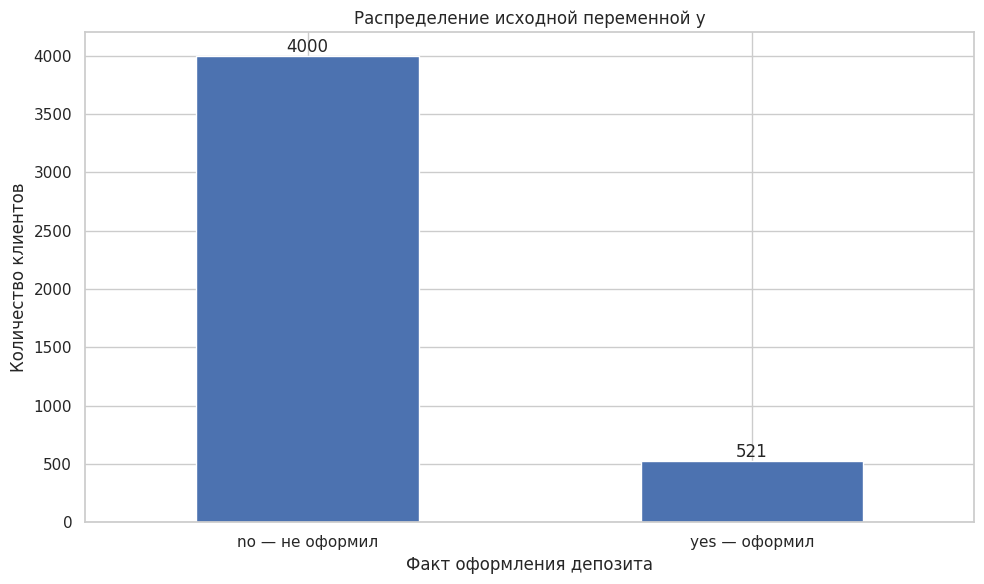

In [7]:
# Сохраняем исходную целевую переменную отдельно для внешней оценки.
# Переменная y не включается в набор признаков и не участвует в кластеризации.
y_external = df["y"].copy()

# Подсчитываем количество объектов каждого класса.
y_counts = y_external.value_counts().reindex(
    ["no", "yes"], fill_value=0
)

# Рассчитываем долю каждого класса в процентах.
y_percentages = (
    y_external
    .value_counts(normalize=True)
    .reindex(["no", "yes"], fill_value=0)
    * 100
)

# Формируем итоговую таблицу.
y_summary = pd.DataFrame({
    "Количество клиентов": y_counts,
    "Доля, %": y_percentages.round(2)
})

display(y_summary)

# Строим диаграмму распределения исходной переменной y.
ax = y_counts.plot(kind="bar")

ax.set_title("Распределение исходной переменной y")
ax.set_xlabel("Факт оформления депозита")
ax.set_ylabel("Количество клиентов")
ax.set_xticklabels(["no — не оформил", "yes — оформил"], rotation=0)

# Подписываем столбцы значениями.
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


#### Вывод о пригодности датасета

В наборе данных присутствует дисбаланс исходной переменной `y`, однако для кластеризации это не является препятствием: алгоритмы не получают эту переменную и не обучаются предсказывать её значения.

Смысл кластеризации в данной работе — выделить группы клиентов по их характеристикам и истории взаимодействия с банком. После получения кластеров можно отдельно проверить, различается ли в них доля клиентов, оформивших депозит.

## 3. Предобработка данных

### 3.1. Формирование набора признаков

Для кластеризации оставим демографические и финансовые характеристики клиентов, а также признаки истории взаимодействия с банком.

Исключаемые столбцы:

- `y` — известная целевая переменная; будет использоваться только для внешней оценки;
- `duration` — продолжительность разговора, которая становится известна после контакта и не является устойчивой характеристикой клиента;
- `day` и `month` — календарные параметры последнего контакта, которые могут группировать клиентов по времени проведения кампании, а не по их профилю.

Столбец `pdays` требует отдельной обработки: значение `-1` означает отсутствие предыдущего контакта. В исходном датасете нет значений `pdays = 0`, поэтому заменим `-1` на `0`: после замены ноль будет однозначно обозначать отсутствие предыдущего контакта. Дополнительный индикатор не добавляем, поскольку эту информацию также отражают `previous = 0` и категория `poutcome = unknown`. При этом `pdays`, `previous` и `poutcome` совместно кодируют факт наличия предыдущих контактов, поэтому их вклад в евклидовы расстояния частично дублируется. Это учитывается при содержательной интерпретации кластеров.

In [8]:
# Целевая переменная хранится отдельно и не входит в X
excluded_columns = ["y", "duration", "day", "month"]
selected_features = [
    "age",
    "balance",
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "campaign",
    "pdays",
    "previous",
    "poutcome"
]

X_raw = df[selected_features].copy()

# Контроль: целевая переменная не должна попасть в матрицу кластеризации
assert "y" not in selected_features
assert "y" not in X_raw.columns
assert set(X_raw.columns) == set(selected_features)

print("Исключённые столбцы:", excluded_columns)
print("Признаки для кластеризации:", selected_features)
print("Размер матрицы признаков до преобразований:", X_raw.shape)
print("Количество значений pdays = -1:", int((X_raw["pdays"] == -1).sum()))
print("Количество исходных значений pdays = 0:", int((X_raw["pdays"] == 0).sum()))
print("Количество клиентов с previous = 0:", int((X_raw["previous"] == 0).sum()))

# Специальное значение -1 заменяем на 0.
# Категория poutcome = unknown сохраняется отдельно.
X_model = X_raw.copy()
X_model["pdays"] = X_model["pdays"].replace(-1, 0)

display(X_model.head())

Исключённые столбцы: ['y', 'duration', 'day', 'month']
Признаки для кластеризации: ['age', 'balance', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'campaign', 'pdays', 'previous', 'poutcome']
Размер матрицы признаков до преобразований: (4521, 13)
Количество значений pdays = -1: 3705
Количество исходных значений pdays = 0: 0
Количество клиентов с previous = 0: 3705


,age,balance,job,marital,education,default,housing,loan,contact,campaign,pdays,previous,poutcome
0,30,1787,unemployed,married,primary,no,no,no,cellular,1,0,0,unknown
1,33,4789,services,married,secondary,no,yes,yes,cellular,1,339,4,failure
2,35,1350,management,single,tertiary,no,yes,no,cellular,1,330,1,failure
3,30,1476,management,married,tertiary,no,yes,yes,unknown,4,0,0,unknown
4,59,0,blue-collar,married,secondary,no,yes,no,unknown,1,0,0,unknown


### 3.2. Обработка экстремальных значений

Для ограничения влияния крайних значений используем границы 1-го и 99-го процентилей. Преобразование применяется к `balance`, `campaign`, `pdays` и `previous`.

Возраст (`age`) не ограничиваем: наблюдаемые значения находятся в правдоподобном диапазоне и могут отражать реальные различия между клиентами. Все строки сохраняются.

In [9]:
# Признаки, для которых ограничиваем крайние значения
columns_to_cap = ["balance", "campaign", "pdays", "previous"]
cap_information = []

for column in columns_to_cap:
    lower_limit = X_model[column].quantile(0.01)
    upper_limit = X_model[column].quantile(0.99)

    changed_count = int(
        ((X_model[column] < lower_limit) | (X_model[column] > upper_limit)).sum()
    )

    X_model[column] = X_model[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

    cap_information.append({
        "Признак": column,
        "Нижняя граница (1%)": lower_limit,
        "Верхняя граница (99%)": upper_limit,
        "Количество ограниченных значений": changed_count
    })

cap_summary = pd.DataFrame(cap_information).set_index("Признак").round(2)
display(cap_summary)

print("Количество объектов после обработки:", X_model.shape[0])

,Нижняя граница (1%),Верхняя граница (99%),Количество ограниченных значений
Признак,,,
balance,-671.4,14194.6,92
campaign,1.0,16.0,43
pdays,0.0,370.0,41
previous,0.0,8.0,34


Количество объектов после обработки: 4521


### 3.3. Кодирование категориальных признаков и стандартизация

Алгоритмы K-means и Agglomerative Clustering используют расстояния между объектами. Поэтому числовые признаки необходимо привести к сопоставимому масштабу.

Для числовых переменных применяется `StandardScaler`: после преобразования среднее значение признака близко к 0, а стандартное отклонение — к 1.

Категориальные переменные преобразуются с помощью `OneHotEncoder`. Это позволяет представить номинальные категории отдельными бинарными столбцами без присвоения им искусственного числового порядка. Бинарные столбцы имеют значения 0 и 1, поэтому дополнительное масштабирование к ним не применяется.

In [10]:
# Автоматически определяем типы признаков после обработки pdays
numeric_features = X_model.select_dtypes(include="number").columns.tolist()
categorical_features = X_model.select_dtypes(exclude="number").columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

# Создаём преобразователь:
# числовые признаки стандартизируются, категориальные кодируются One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ],
    verbose_feature_names_out=False
)

# Обучаем преобразователь и формируем итоговую матрицу признаков
X_scaled = preprocessor.fit_transform(X_model)
feature_names = preprocessor.get_feature_names_out()

# Итоговая проверка: y не должна попасть в матрицу признаков.
assert "y" not in selected_features
assert "y" not in feature_names

print("Размер матрицы после преобразования:", X_scaled.shape)
print("Количество признаков после кодирования:", len(feature_names))

# Проверяем результат стандартизации числовых признаков
scaled_numeric = pd.DataFrame(
    X_scaled[:, :len(numeric_features)],
    columns=numeric_features
)

scaling_check = pd.DataFrame({
    "Среднее после StandardScaler": scaled_numeric.mean(),
    "Стандартное отклонение после StandardScaler": scaled_numeric.std(ddof=0),
    "Минимум": scaled_numeric.min(),
    "Максимум": scaled_numeric.max()
}).round(3)

display(scaling_check)

# Проверяем, что бинарные признаки One-Hot Encoding имеют значения 0 или 1
encoded_categorical = X_scaled[:, len(numeric_features):]
print(
    "Уникальные значения в закодированных категориальных признаках:",
    np.unique(encoded_categorical)
)

Числовые признаки: ['age', 'balance', 'campaign', 'pdays', 'previous']
Категориальные признаки: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']
Размер матрицы после преобразования: (4521, 37)
Количество признаков после кодирования: 37


,Среднее после StandardScaler,Стандартное отклонение после StandardScaler,Минимум,Максимум
age,-0.0,1.0,-2.096,4.334
balance,-0.0,1.0,-0.836,5.295
campaign,0.0,1.0,-0.657,5.055
pdays,-0.0,1.0,-0.417,3.476
previous,-0.0,1.0,-0.364,5.417


Уникальные значения в закодированных категориальных признаках: [0. 1.]


#### Вывод по предобработке

После выбора признаков, обработки специального значения `pdays` и ограничения крайних значений получена матрица из 4521 объекта. Числовые признаки стандартизированы с помощью `StandardScaler`, а категориальные преобразованы в бинарные признаки.

В результате One-Hot Encoding количество столбцов увеличилось: каждая категория представлена отдельным бинарным признаком. Итоговая матрица имеет 37 признаков. Целевая переменная `y` в неё не включена.

### 3.4. Матрица диаграмм рассеивания

Построим матрицу диаграмм рассеивания для основных числовых признаков, участвующих в кластеризации. Для ускорения визуализации используем случайную выборку из 700 объектов.

Матрица позволяет оценить взаимосвязи признаков, асимметрию распределений и наличие очевидных групп. Поскольку часть признаков имеет сильную асимметрию и большое количество нулевых значений, на двумерных проекциях могут быть не видны все особенности многомерной структуры.

В матрице показаны стандартизированные числовые признаки после обработки крайних значений. Поэтому шкалы осей становятся сопоставимыми, а матрица отражает числовую часть признаков, переданных алгоритмам. Плотность точек и отсутствие чётких разделённых облаков не являются ошибкой: это отражает особенности самих данных.

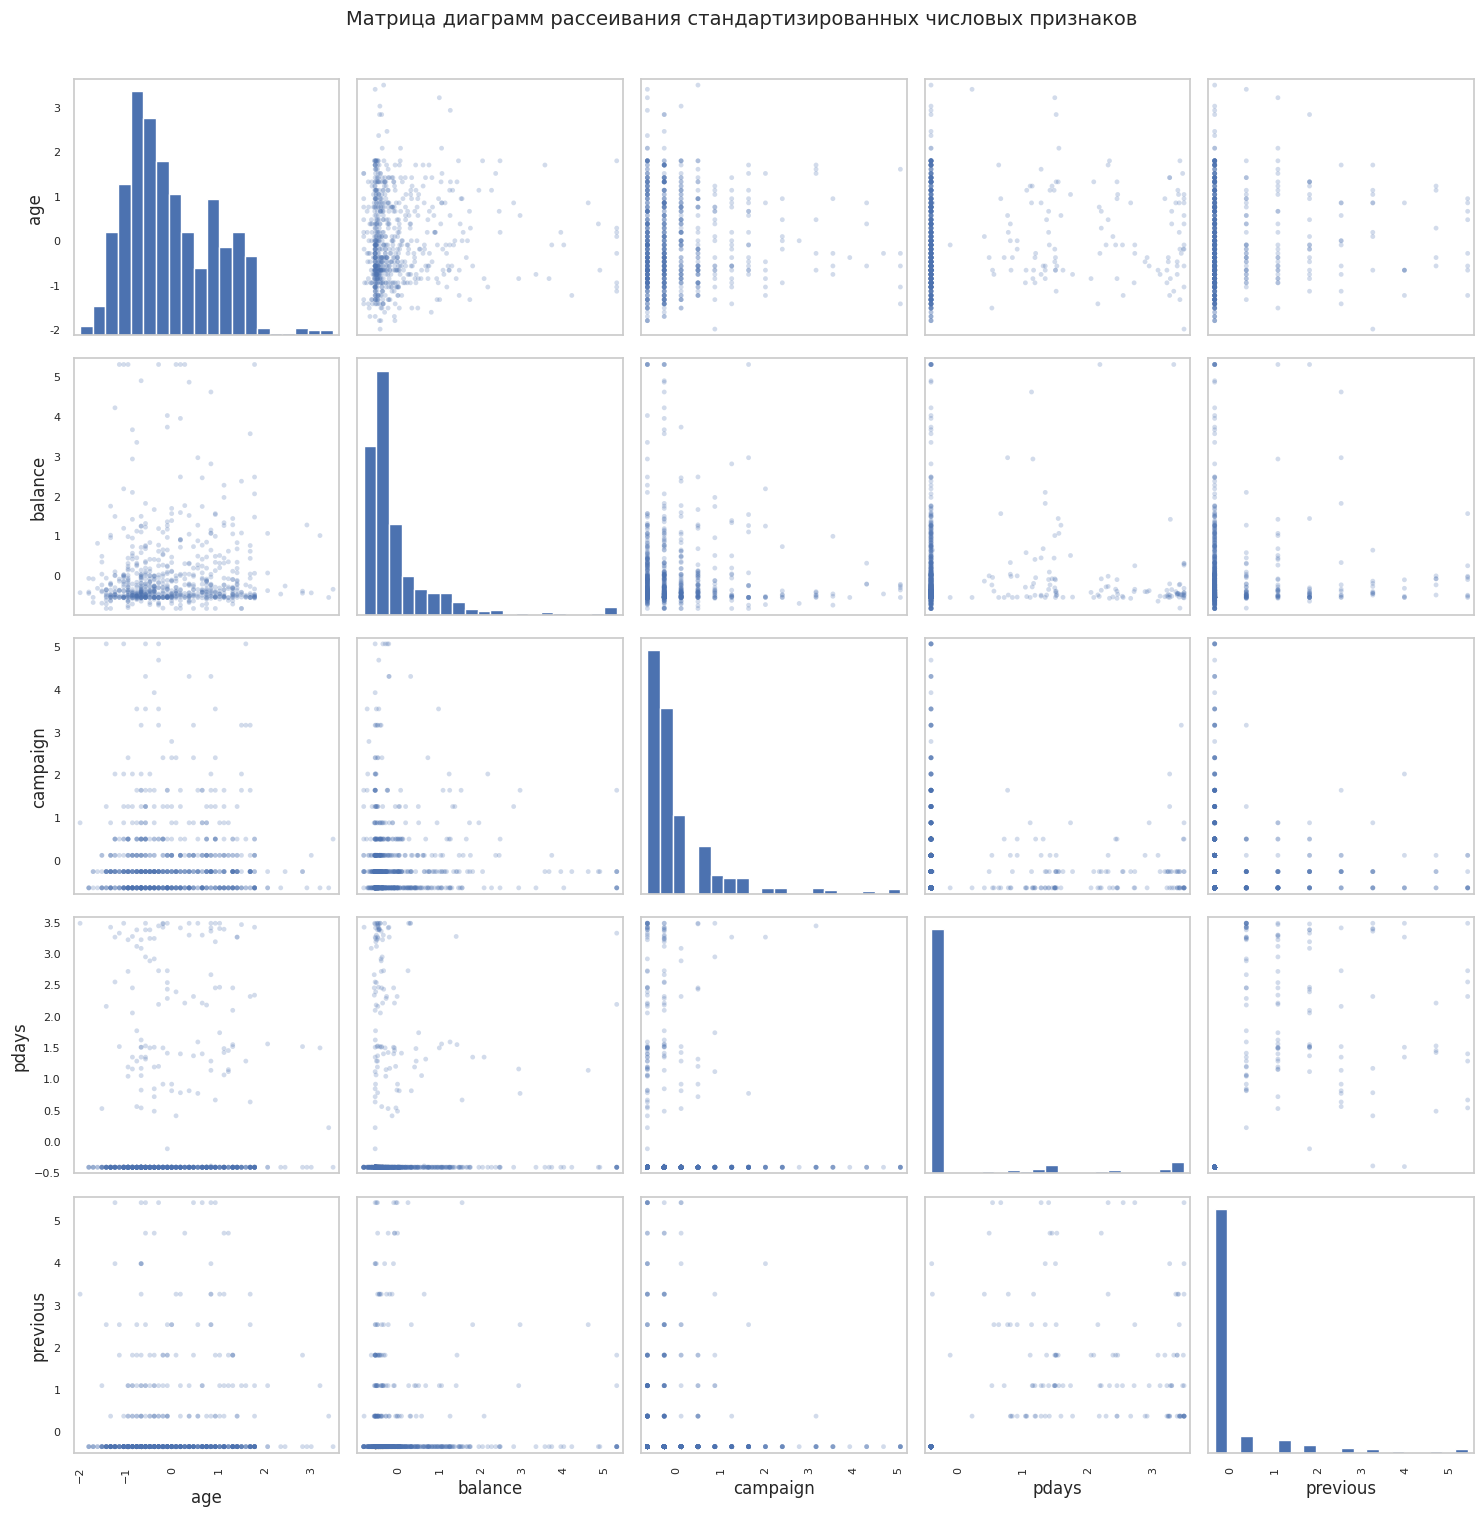

In [11]:
# Для матрицы используем стандартизированные числовые признаки.
# Категориальные One-Hot признаки в эту матрицу не включаем.
pairplot_data = pd.DataFrame(
    X_scaled[:, :len(numeric_features)],
    columns=numeric_features
)
pairplot_sample = pairplot_data.sample(
    n=min(700, len(pairplot_data)),
    random_state=RANDOM_STATE
)

from pandas.plotting import scatter_matrix

scatter_axes = scatter_matrix(
    pairplot_sample,
    figsize=(15, 15),
    diagonal="hist",
    alpha=0.25,
    s=12,
    marker="o",
    grid=False,
    hist_kwds={"bins": 20, "edgecolor": "white"},
    range_padding=0.05
)

for ax in np.asarray(scatter_axes).ravel():
    ax.grid(False)
    ax.tick_params(labelsize=8)

plt.suptitle(
    "Матрица диаграмм рассеивания стандартизированных числовых признаков",
    y=1.01,
    fontsize=14
)
plt.tight_layout()
plt.show()

#### Вывод по матрице диаграмм рассеивания

На двумерных диаграммах не наблюдается нескольких явно разделённых вытянутых или нелинейных групп по всем числовым характеристикам. При этом признаки истории контактов имеют выраженную неоднородность: у значительной части клиентов предыдущие контакты отсутствуют, а у меньшей части есть история взаимодействия. Следовательно, ожидаются группы разного размера; их плотность и границы не выглядят одинаковыми по всем признакам.

Для сравнения выбраны два метода, работающие с расстояниями, но использующие разные механизмы: K-means распределяет объекты относительно центров, а Agglomerative Clustering последовательно объединяет ближайшие группы и показывает иерархию слияний. Метод Ward ориентирован на компактные группы и минимизацию внутрикластерного разброса. Такое сравнение позволяет проверить, воспроизводится ли найденная структура при двух подходах. DBSCAN не выбран как основной метод: в многомерном пространстве после One-Hot Encoding подбор единого радиуса `eps` затруднён, особенно при различающейся плотности групп.

- **K-means** — позволяет выделить группы вокруг центров и исследовать влияние числа кластеров;
- **Agglomerative Clustering** с методом объединения Ward — формирует иерархию групп и позволяет визуально оценить структуру с помощью дендрограммы.

DBSCAN не выбирается в качестве основного метода: после One-Hot Encoding пространство признаков становится многомерным, а результат плотностной кластеризации может быть чувствителен к выбору `eps` и `min_samples`. Gaussian Mixture также не является первым выбором, поскольку бинарные закодированные категории и специальные значения не соответствуют предположению о смеси многомерных нормальных распределений.

## 4. Подбор количества кластеров

### 4.1. Метод локтя и силуэтный анализ для K-means

Для K-means исследуем значения количества кластеров от 2 до 8.

Метод локтя анализирует изменение внутрикластерной суммы квадратов расстояний (`inertia_`). При увеличении числа кластеров эта величина уменьшается, поэтому ищется участок, после которого улучшение становится менее заметным.

Силуэтный коэффициент оценивает, насколько объект близок к своему кластеру по сравнению с ближайшим другим кластером. Значение находится в диапазоне от -1 до 1; чем оно выше, тем лучше разделение.

,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,Размеры кластеров
Количество кластеров,,,,,
2,31380.2583,0.3075,1087.3427,1.5554,"[3756, 765]"
3,28358.8590,0.1460,842.1399,2.1420,"[1460, 2340, 721]"
4,25750.5073,0.1562,770.6719,1.8608,"[275, 720, 1325, 2201]"
5,23380.3467,0.1567,750.9089,1.6692,"[1262, 242, 685, 263, 2069]"
6,22131.4385,0.1582,685.4441,1.7383,"[1260, 263, 2060, 510, 241, 187]"
7,20910.8273,0.1338,648.3272,1.8309,"[1008, 187, 1235, 253, 1125, 225, 488]"
8,20140.6811,0.1274,601.4842,1.8903,"[237, 187, 221, 939, 479, 786, 910, 762]"


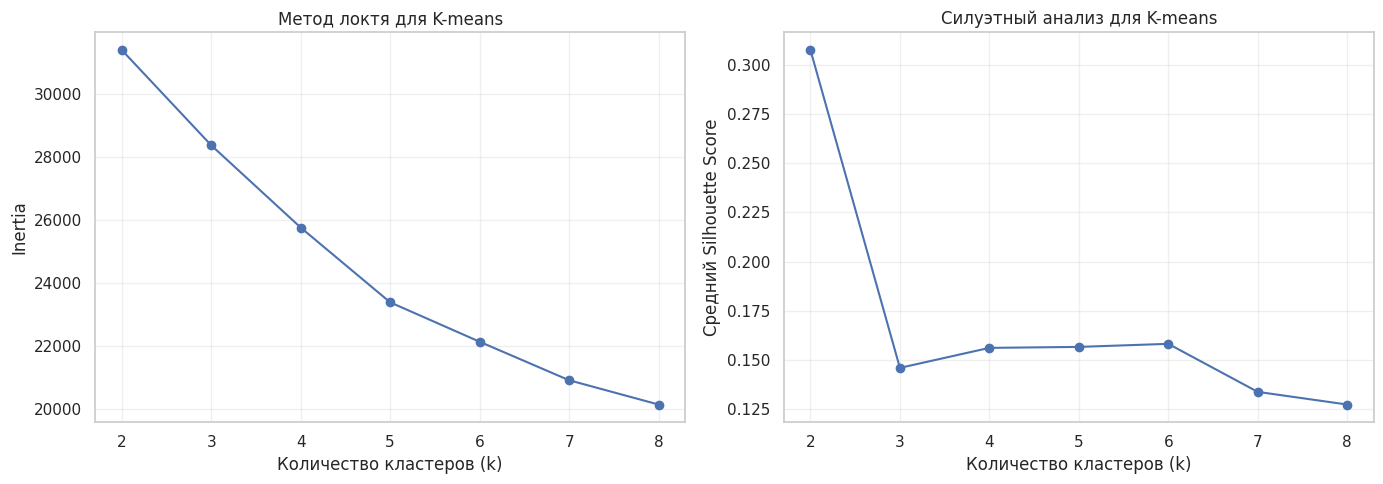

Лучшее количество кластеров по Silhouette для K-means: 2


In [12]:
k_values = range(2, 9)
kmeans_search_rows = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE
    )
    labels = model.fit_predict(X_scaled)

    kmeans_search_rows.append({
        "Количество кластеров": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Размеры кластеров": np.bincount(labels).tolist()
    })

kmeans_search_df = pd.DataFrame(kmeans_search_rows).set_index("Количество кластеров")
display(kmeans_search_df.round(4))

# Графики метода локтя и силуэтного анализа
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    kmeans_search_df.index,
    kmeans_search_df["Inertia"],
    marker="o"
)
axes[0].set_title("Метод локтя для K-means")
axes[0].set_xlabel("Количество кластеров (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    kmeans_search_df.index,
    kmeans_search_df["Silhouette"],
    marker="o"
)
axes[1].set_title("Силуэтный анализ для K-means")
axes[1].set_xlabel("Количество кластеров (k)")
axes[1].set_ylabel("Средний Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_k_kmeans = int(kmeans_search_df["Silhouette"].idxmax())
print("Лучшее количество кластеров по Silhouette для K-means:", best_k_kmeans)

#### Вывод по подбору количества кластеров для K-means

При увеличении `k` значение `Inertia` последовательно уменьшается. При этом выраженного резкого «локтя» на графике нет, поэтому выбирать количество кластеров только по этому критерию было бы неоднозначно.

Силуэтный анализ показывает наилучшее качество при **k = 2**. При переходе к трём и более кластерам средний силуэтный коэффициент заметно снижается. Дополнительно при `k = 2` достигается наибольшее значение индекса Calinski–Harabasz среди исследованных вариантов.

По совокупности критериев для итоговой модели K-means выбирается два кластера.

### 4.2. Дендрограмма для иерархической кластеризации

Иерархическая агломеративная кластеризация начинает с отдельных объектов и последовательно объединяет наиболее близкие группы. Метод Ward выбирает объединения, которые минимально увеличивают внутрикластерную сумму квадратов.

Полная дендрограмма для всех 4521 объектов была бы перегружена, поэтому для её построения используем случайную выборку из 400 наблюдений. Итоговая модель Agglomerative Clustering далее будет обучена на полном наборе данных.

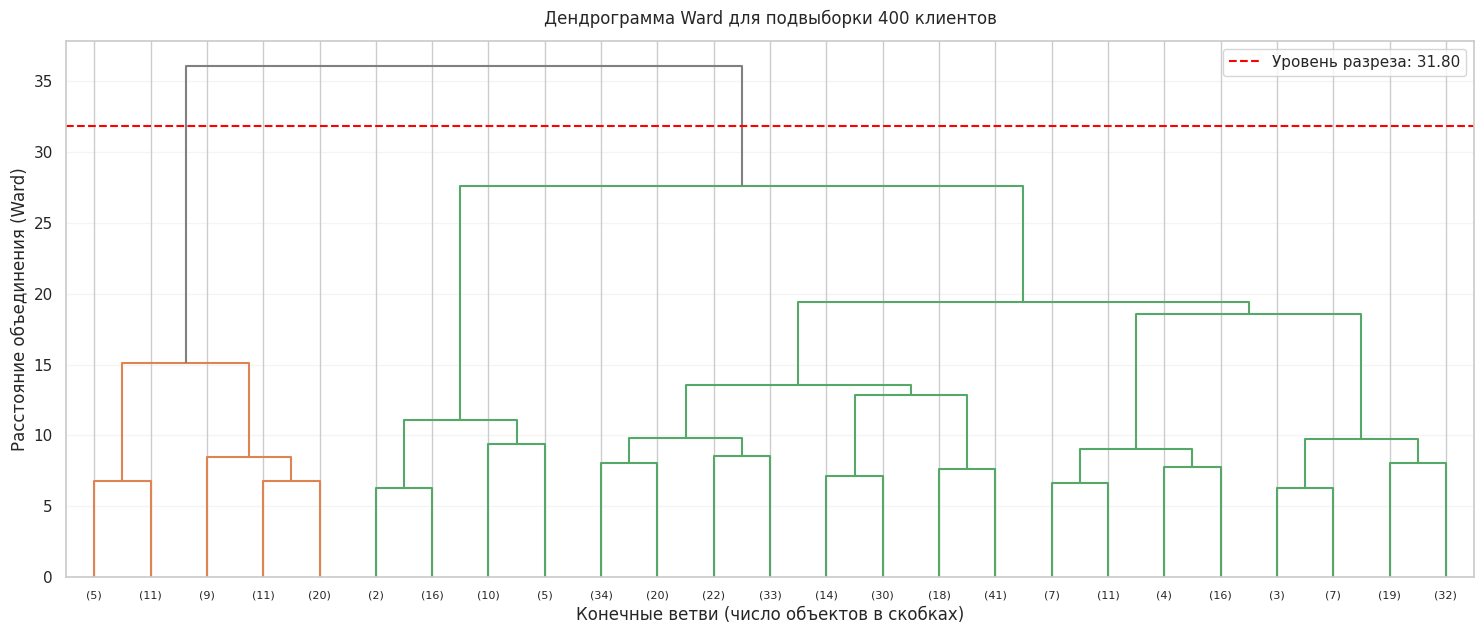

Объектов в подвыборке: 400
Высота последнего объединения: 36.019
Высота предпоследнего объединения: 27.584
Выбранный уровень разреза: 31.801
Размеры групп на подвыборке:


,Количество объектов
Группа,
1,56
2,344


Количество групп: 2


In [13]:
# Строим дендрограмму на воспроизводимой выборке: полное дерево для 4521 строк было бы слишком перегружено.
rng = np.random.default_rng(RANDOM_STATE)
dendrogram_indices = rng.choice(
    X_scaled.shape[0],
    size=min(400, X_scaled.shape[0]),
    replace=False
)
X_dendrogram = X_scaled[dendrogram_indices]

# Метод Ward минимизирует прирост внутрикластерной дисперсии при каждом объединении.
linkage_matrix = linkage(
    X_dendrogram,
    method="ward",
    metric="euclidean"
)

# Порог разреза выбираем между двумя наибольшими итоговыми расстояниями объединения.
cut_threshold = (linkage_matrix[-1, 2] + linkage_matrix[-2, 2]) / 2

fig, ax = plt.subplots(figsize=(15, 6.5))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=25,
    show_leaf_counts=True,
    leaf_rotation=0,
    leaf_font_size=8,
    color_threshold=cut_threshold,
    above_threshold_color="grey",
    ax=ax
)
ax.axhline(
    y=cut_threshold,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Уровень разреза: {cut_threshold:.2f}"
)
ax.set_title(
    "Дендрограмма Ward для подвыборки 400 клиентов",
    pad=12
)
ax.set_xlabel(
    "Конечные ветви (число объектов в скобках)"
)
ax.set_ylabel("Расстояние объединения (Ward)")
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

print("Объектов в подвыборке:", len(dendrogram_indices))
print("Высота последнего объединения:", round(linkage_matrix[-1, 2], 3))
print("Высота предпоследнего объединения:", round(linkage_matrix[-2, 2], 3))
print("Выбранный уровень разреза:", round(cut_threshold, 3))

sample_dendrogram_labels = fcluster(
    linkage_matrix,
    t=cut_threshold,
    criterion="distance"
)
sample_dendrogram_sizes = (
    pd.Series(sample_dendrogram_labels, name="Группа")
    .value_counts()
    .sort_index()
    .to_frame("Количество объектов")
)
print("Размеры групп на подвыборке:")
display(sample_dendrogram_sizes)
print("Количество групп:", sample_dendrogram_sizes.shape[0])

#### Вывод по дендрограмме

Дендрограмма построена на случайной подвыборке из 400 клиентов, поскольку полное дерево для 4521 объекта было бы слишком перегружено. Параметр `p=25` показывает 25 конечных ветвей, а числа в скобках под ними — количество исходных объектов в каждой свёрнутой ветви.

Красная пунктирная линия обозначает уровень разреза. Горизонтальный разрез на этой высоте образует две группы; их размеры на подвыборке составляют 56 и 344 клиента, что также показано в таблице под графиком. Это визуальная оценка на подвыборке, а выбор `k=2` дополнительно проверяется силуэтным анализом на полном наборе данных. Итоговая модель Agglomerative Clustering обучается на всех 4521 клиентах.

### 4.3. Проверка количества кластеров для Agglomerative Clustering

Дополнительно проверим значения `k` от 2 до 8 по внутренним метрикам. Это позволит сопоставить визуальную оценку дендрограммы с количественными результатами.

In [14]:
agglomerative_search_rows = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )
    labels = model.fit_predict(X_scaled)

    agglomerative_search_rows.append({
        "Количество кластеров": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Размеры кластеров": np.bincount(labels).tolist()
    })

agglomerative_search_df = (
    pd.DataFrame(agglomerative_search_rows)
    .set_index("Количество кластеров")
)
display(agglomerative_search_df.round(4))

best_k_agglomerative = int(agglomerative_search_df["Silhouette"].idxmax())
print(
    "Лучшее количество кластеров по Silhouette для Agglomerative Clustering:",
    best_k_agglomerative
)

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Размеры кластеров
Количество кластеров,,,,
2,0.3033,1016.2418,1.5446,"[3817, 704]"
3,0.2138,738.9224,1.6698,"[3469, 704, 348]"
4,0.1990,656.7732,1.6844,"[3122, 704, 348, 347]"
5,0.1450,617.9971,1.8155,"[704, 2472, 348, 347, 650]"
6,0.1457,555.0329,1.7747,"[2472, 611, 348, 347, 650, 93]"
7,0.0903,514.6227,2.0622,"[1230, 611, 348, 347, 650, 93, 1242]"
8,0.0809,472.4381,2.0060,"[348, 611, 1242, 347, 650, 93, 829, 401]"


Лучшее количество кластеров по Silhouette для Agglomerative Clustering: 2


#### Вывод по подбору количества кластеров для Agglomerative Clustering

Наибольшее значение Silhouette получено при `k = 2`. При дальнейшем увеличении количества кластеров показатель в целом снижается, хотя между отдельными соседними значениями есть небольшие колебания. Это согласуется с дендрограммой и результатами K-means.

Таким образом, для обоих алгоритмов используется **два кластера**. Решение подтверждается анализом внутренних метрик и структуры иерархического дерева.

## 5. Реализация алгоритмов кластеризации

### 5.1. Алгоритм K-means

В модели явно задаются:

- `n_clusters` — количество кластеров;
- `init="k-means++"` — способ выбора начальных центров;
- `n_init=10` — количество запусков с разными начальными центрами;
- `random_state=42` — фиксация случайного состояния для воспроизводимости.

После обучения получим метки кластеров, центры и значение `inertia_`.

In [15]:
kmeans_model = KMeans(
    n_clusters=best_k_kmeans,
    init="k-means++",
    n_init=10,
    random_state=RANDOM_STATE
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

print("Размер массива меток:", kmeans_labels.shape)
print("Фактическое количество кластеров:", len(np.unique(kmeans_labels)))
print("Значение inertia_:", round(kmeans_model.inertia_, 3))
print("Размеры кластеров:")
display(
    pd.Series(kmeans_labels, name="Кластер")
    .value_counts()
    .sort_index()
    .to_frame("Количество объектов")
)

print("Размерность матрицы центров:", kmeans_model.cluster_centers_.shape)

Размер массива меток: (4521,)
Фактическое количество кластеров: 2
Значение inertia_: 31380.258
Размеры кластеров:


,Количество объектов
Кластер,
0,3756
1,765


Размерность матрицы центров: (2, 37)


### 5.2. Иерархическая кластеризация Agglomerative Clustering

Для иерархической кластеризации используем:

- `n_clusters` — два итоговых кластера;
- `linkage="ward"` — объединение, минимизирующее рост внутрикластерной суммы квадратов;
- `metric="euclidean"` — евклидова метрика расстояния.

В отличие от K-means, Agglomerative Clustering не возвращает центры кластеров напрямую. Их можно вычислить отдельно как средние векторы объектов, попавших в каждый кластер.

In [16]:
agglomerative_model = AgglomerativeClustering(
    n_clusters=best_k_agglomerative,
    linkage="ward",
    metric="euclidean"
)

agglomerative_labels = agglomerative_model.fit_predict(X_scaled)

print("Размер массива меток:", agglomerative_labels.shape)
print("Фактическое количество кластеров:", len(np.unique(agglomerative_labels)))
print("Размеры кластеров:")
display(
    pd.Series(agglomerative_labels, name="Кластер")
    .value_counts()
    .sort_index()
    .to_frame("Количество объектов")
)

Размер массива меток: (4521,)
Фактическое количество кластеров: 2
Размеры кластеров:


,Количество объектов
Кластер,
0,3817
1,704


## 6. Оценка качества кластеризации

### 6.1. Внутренние метрики качества

Для оценки разбиения используем три внутренние метрики:

- **Silhouette Score** — оценивает близость объектов к своему кластеру и удалённость от соседних кластеров; выше — лучше.
- **Calinski–Harabasz Index** — соотношение межкластерного и внутрикластерного разброса; выше — лучше.
- **Davies–Bouldin Index** — оценивает сходство кластеров с учётом разброса и расстояния между центрами; ниже — лучше.

Эти метрики не требуют исходных меток классов и оценивают геометрию полученного разбиения.

In [17]:
def calculate_internal_metrics(X, labels):
    """Рассчитывает внутренние метрики с проверкой допустимости разбиения."""
    labels = np.asarray(labels)

    # Для алгоритмов с шумом (например, DBSCAN) исключаем метку -1
    valid_mask = labels != -1
    X_valid = X[valid_mask]
    labels_valid = labels[valid_mask]

    unique_labels = np.unique(labels_valid)
    number_of_clusters = len(unique_labels)
    number_of_objects = len(labels_valid)

    # Метрики не определены для одного кластера или ситуации,
    # когда каждый объект образует отдельный кластер
    if number_of_clusters < 2 or number_of_clusters >= number_of_objects:
        return {
            "Silhouette": np.nan,
            "Calinski-Harabasz": np.nan,
            "Davies-Bouldin": np.nan
        }

    return {
        "Silhouette": silhouette_score(X_valid, labels_valid),
        "Calinski-Harabasz": calinski_harabasz_score(X_valid, labels_valid),
        "Davies-Bouldin": davies_bouldin_score(X_valid, labels_valid)
    }


kmeans_metrics = calculate_internal_metrics(X_scaled, kmeans_labels)
agglomerative_metrics = calculate_internal_metrics(X_scaled, agglomerative_labels)

internal_comparison = pd.DataFrame(
    [kmeans_metrics, agglomerative_metrics],
    index=["K-means", "Agglomerative Clustering"]
).round(4)

display(internal_comparison)

# Проверяем количество шумовых объектов и размеры кластеров
for method_name, labels in [
    ("K-means", kmeans_labels),
    ("Agglomerative Clustering", agglomerative_labels)
]:
    noise_count = int(np.sum(labels == -1))
    print(f"{method_name}: шумовых объектов = {noise_count}")

# Проверяем защиту от некорректных ситуаций:
# 1) все объекты отнесены к одному кластеру;
# 2) все объекты помечены как шум (метка -1).
print("Проверка одного кластера:", calculate_internal_metrics(X_scaled[:10], np.zeros(10)))
print("Проверка всех объектов как шума:", calculate_internal_metrics(X_scaled[:10], np.full(10, -1)))

,Silhouette,Calinski-Harabasz,Davies-Bouldin
K-means,0.3075,1087.3427,1.5554
Agglomerative Clustering,0.3033,1016.2418,1.5446


K-means: шумовых объектов = 0
Agglomerative Clustering: шумовых объектов = 0
Проверка одного кластера: {'Silhouette': nan, 'Calinski-Harabasz': nan, 'Davies-Bouldin': nan}
Проверка всех объектов как шума: {'Silhouette': nan, 'Calinski-Harabasz': nan, 'Davies-Bouldin': nan}


### 6.2. Внутрикластерные расстояния, компактность и центры

Компактность в данной работе определяется как среднее евклидово расстояние объектов до центра своего кластера в стандартизированном пространстве признаков. Чем меньше это расстояние, тем ближе объекты расположены к центру группы.

Расстояние между кластерами рассчитывается как евклидово расстояние между их центрами. Для K-means центры возвращаются атрибутом `cluster_centers_`. Для Agglomerative Clustering центры вычисляются как средние векторы объектов каждого кластера.

In [18]:
def calculate_centroids(X, labels):
    """Вычисляет центры кластеров как средние векторы объектов."""
    labels = np.asarray(labels)
    cluster_ids = sorted(label for label in np.unique(labels) if label != -1)
    centroids = np.vstack([
        X[labels == cluster_id].mean(axis=0)
        for cluster_id in cluster_ids
    ])
    return cluster_ids, centroids


def calculate_compactness(X, labels, cluster_ids, centroids):
    """Рассчитывает расстояния объектов до центра каждого кластера."""
    rows = []

    for cluster_id, centroid in zip(cluster_ids, centroids):
        cluster_points = X[np.asarray(labels) == cluster_id]
        distances = np.linalg.norm(cluster_points - centroid, axis=1)

        rows.append({
            "Кластер": cluster_id,
            "Количество объектов": len(cluster_points),
            "Среднее расстояние до центра": distances.mean(),
            "Медианное расстояние до центра": np.median(distances),
            "Максимальное расстояние до центра": distances.max()
        })

    return pd.DataFrame(rows).set_index("Кластер")


# Центры K-means берём непосредственно из обученной модели
kmeans_cluster_ids = list(range(kmeans_model.n_clusters))
kmeans_centroids = kmeans_model.cluster_centers_

# Для Agglomerative Clustering вычисляем центры самостоятельно
agg_cluster_ids, agg_centroids = calculate_centroids(
    X_scaled,
    agglomerative_labels
)

kmeans_compactness = calculate_compactness(
    X_scaled,
    kmeans_labels,
    kmeans_cluster_ids,
    kmeans_centroids
)

agg_compactness = calculate_compactness(
    X_scaled,
    agglomerative_labels,
    agg_cluster_ids,
    agg_centroids
)

print("Компактность кластеров K-means:")
display(kmeans_compactness.round(4))

print("Компактность кластеров Agglomerative Clustering:")
display(agg_compactness.round(4))

# Расстояния между центрами кластеров
kmeans_center_distances = pd.DataFrame(
    pairwise_distances(kmeans_centroids),
    index=[f"Кластер {i}" for i in kmeans_cluster_ids],
    columns=[f"Кластер {i}" for i in kmeans_cluster_ids]
)

agg_center_distances = pd.DataFrame(
    pairwise_distances(agg_centroids),
    index=[f"Кластер {i}" for i in agg_cluster_ids],
    columns=[f"Кластер {i}" for i in agg_cluster_ids]
)

print("Расстояния между центрами K-means:")
display(kmeans_center_distances.round(4))

print("Расстояния между центрами Agglomerative Clustering:")
display(agg_center_distances.round(4))

# Показываем стандартизированные координаты центров по числовым признакам
centers_numeric = pd.DataFrame(
    kmeans_centroids[:, :len(numeric_features)],
    columns=numeric_features,
    index=[f"Кластер {i}" for i in kmeans_cluster_ids]
)
print("Координаты центров K-means по числовым признакам (в единицах StandardScaler):")
display(centers_numeric.round(3))

agg_centers_numeric = pd.DataFrame(
    agg_centroids[:, :len(numeric_features)],
    columns=numeric_features,
    index=[f"Кластер {i}" for i in agg_cluster_ids]
)
print("Координаты центров Agglomerative Clustering по числовым признакам:")
display(agg_centers_numeric.round(3))

Компактность кластеров K-means:


,Количество объектов,Среднее расстояние до центра,Медианное расстояние до центра,Максимальное расстояние до центра
Кластер,,,,
0,3756,2.4204,2.2165,7.5608
1,765,2.9409,2.6978,6.6151


Компактность кластеров Agglomerative Clustering:


,Количество объектов,Среднее расстояние до центра,Медианное расстояние до центра,Максимальное расстояние до центра
Кластер,,,,
0,3817,2.4509,2.2306,7.5632
1,704,2.9055,2.6782,6.6517


Расстояния между центрами K-means:


,Кластер 0,Кластер 1
Кластер 0,0.0000,3.4468
Кластер 1,3.4468,0.0000


... (2 outputs left out)

Координаты центров K-means по числовым признакам (в единицах StandardScaler):


,age,balance,campaign,pdays,previous
Кластер 0,-0.003,-0.017,0.053,-0.405,-0.354
Кластер 1,0.017,0.083,-0.263,1.990,1.736


Координаты центров Agglomerative Clustering по числовым признакам:


,age,balance,campaign,pdays,previous
Кластер 0,0.037,-0.013,0.049,-0.375,-0.325
Кластер 1,-0.201,0.072,-0.265,2.036,1.762


#### Вывод по компактности и расстояниям

Среднее расстояние до центра позволяет сравнить разброс объектов внутри каждой группы, а расстояние между центрами — оценить разделённость кластеров. Эти величины рассчитаны в стандартизированном пространстве признаков, поэтому их нельзя трактовать как рубли, годы или количество контактов.

Центры K-means получены непосредственно из модели. Центры иерархической кластеризации рассчитаны отдельно как средние векторы объектов с одинаковой меткой.

Расстояние между центрами составляет 3,4468 для K-means и 3,4677 для Agglomerative Clustering. Средние расстояния объектов до своих центров находятся примерно в диапазоне 2,42–2,94. Это указывает на различимость двух групп, но не на полное разделение объектов без перекрытия. Такой вывод согласуется со средним коэффициентом силуэта около 0,30.

### 6.3. Внешние метрики качества

Поскольку в исходном датасете известна переменная `y`, можно дополнительно сравнить полученные кластеры с фактом оформления депозита.

Для этого используются:

- **ARI (Adjusted Rand Index)** — скорректированный индекс Rand;
- **NMI (Normalized Mutual Information)** — нормированная взаимная информация;
- **Homogeneity** — степень однородности кластеров относительно исходных классов;
- **Completeness** — степень объединения объектов одного класса в общие кластеры;
- **V-measure** — гармоническое среднее Homogeneity и Completeness.

Эти метрики сравнивают структуру двух разбиений и не зависят от конкретных номеров кластеров: перестановка меток `0` и `1` не меняет результат.

In [19]:
# Кодируем исходную метку только для расчёта внешних метрик
# y_external не участвовала в выборе признаков и обучении моделей
y_true = y_external.map({"no": 0, "yes": 1}).to_numpy()

external_rows = []

for method_name, labels in [
    ("K-means", kmeans_labels),
    ("Agglomerative Clustering", agglomerative_labels)
]:
    external_rows.append({
        "Метод": method_name,
        "ARI": adjusted_rand_score(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "Homogeneity": homogeneity_score(y_true, labels),
        "Completeness": completeness_score(y_true, labels),
        "V-measure": v_measure_score(y_true, labels)
    })

external_comparison = pd.DataFrame(external_rows).set_index("Метод").round(4)
display(external_comparison)

# Сопоставляем кластеры с исходной переменной y
kmeans_y_table = pd.crosstab(
    pd.Series(kmeans_labels, name="Кластер K-means"),
    y_external,
    normalize="index"
) * 100

agg_y_table = pd.crosstab(
    pd.Series(agglomerative_labels, name="Кластер Agglomerative"),
    y_external,
    normalize="index"
) * 100

print("Распределение y внутри кластеров K-means, %:")
display(kmeans_y_table.round(2))

print("Распределение y внутри кластеров Agglomerative Clustering, %:")
display(agg_y_table.round(2))

,ARI,NMI,Homogeneity,Completeness,V-measure
Метод,,,,,
K-means,0.0969,0.0204,0.0231,0.0182,0.0204
Agglomerative Clustering,0.0790,0.0136,0.0150,0.0124,0.0136


Распределение y внутри кластеров K-means, %:


y,no,yes
Кластер K-means,,
0,90.47,9.53
1,78.69,21.31


Распределение y внутри кластеров Agglomerative Clustering, %:


y,no,yes
Кластер Agglomerative,,
0,89.99,10.01
1,80.26,19.74


#### Вывод по внешним метрикам

Внешние метрики показывают, насколько полученные группы совпадают с исходным разделением клиентов по факту оформления депозита. Их значения следует интерпретировать осторожно: цель кластеризации — найти сходство объектов по выбранным характеристикам, а не обязательно восстановить переменную `y`.

Низкое совпадение с `y` не означает автоматически, что кластеризация выполнена неправильно. В данном исследовании алгоритмы в первую очередь выделяют различия в истории контактов с банком, тогда как оформление депозита зависит от большего числа факторов.

## 7. Исследование влияния параметров и устойчивости кластеризации

### 7.1. Влияние количества кластеров на качество K-means

Количество кластеров `k` влияет на размеры групп, внутрикластерный разброс и разделённость объектов. Для оценки этого влияния используем таблицу и графики, построенные на этапе подбора `k`.

,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,Размеры кластеров
Количество кластеров,,,,,
2,31380.2583,0.3075,1087.3427,1.5554,"[3756, 765]"
3,28358.8590,0.1460,842.1399,2.1420,"[1460, 2340, 721]"
4,25750.5073,0.1562,770.6719,1.8608,"[275, 720, 1325, 2201]"
5,23380.3467,0.1567,750.9089,1.6692,"[1262, 242, 685, 263, 2069]"
6,22131.4385,0.1582,685.4441,1.7383,"[1260, 263, 2060, 510, 241, 187]"
7,20910.8273,0.1338,648.3272,1.8309,"[1008, 187, 1235, 253, 1125, 225, 488]"
8,20140.6811,0.1274,601.4842,1.8903,"[237, 187, 221, 939, 479, 786, 910, 762]"


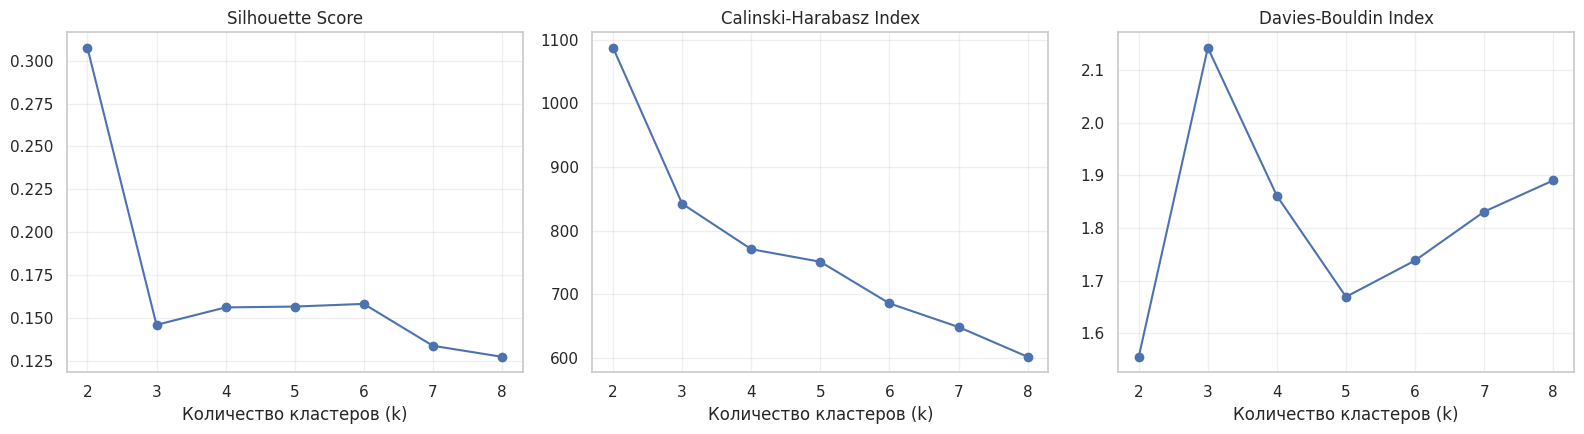

In [20]:
parameter_effect = kmeans_search_df[
    ["Inertia", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin", "Размеры кластеров"]
].copy()
display(parameter_effect.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(parameter_effect.index, parameter_effect["Silhouette"], marker="o")
axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("Количество кластеров (k)")
axes[0].grid(alpha=0.3)

axes[1].plot(parameter_effect.index, parameter_effect["Calinski-Harabasz"], marker="o")
axes[1].set_title("Calinski-Harabasz Index")
axes[1].set_xlabel("Количество кластеров (k)")
axes[1].grid(alpha=0.3)

axes[2].plot(parameter_effect.index, parameter_effect["Davies-Bouldin"], marker="o")
axes[2].set_title("Davies-Bouldin Index")
axes[2].set_xlabel("Количество кластеров (k)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Вывод по влиянию количества кластеров

При увеличении `k` внутрикластерная сумма квадратов уменьшается, поскольку объекты распределяются между большим количеством центров. Однако это не означает автоматического улучшения кластеризации.

Наилучшие значения Silhouette и Calinski–Harabasz получены при `k = 2`. При большем количестве кластеров качество разделения снижается, а часть групп становится сравнительно небольшой. Поэтому два кластера являются наиболее обоснованным вариантом среди проверенных значений.

### 7.2. Проверка устойчивости K-means

Для оценки устойчивости повторим обучение K-means с одинаковым количеством кластеров, но с разными значениями `random_state`. Затем сравним полученные разбиения с помощью ARI.

Если значения ARI близки к 1, алгоритм формирует практически одинаковые группы при разных начальных случайных состояниях.

In [21]:
random_states = [0, 7, 21, 42, 100]
repeated_labels = {}

for seed in random_states:
    model = KMeans(
        n_clusters=best_k_kmeans,
        init="k-means++",
        n_init=10,
        random_state=seed
    )
    repeated_labels[seed] = model.fit_predict(X_scaled)

stability_rows = []

for seed_a, seed_b in combinations(random_states, 2):
    stability_rows.append({
        "random_state 1": seed_a,
        "random_state 2": seed_b,
        "ARI между разбиениями": adjusted_rand_score(
            repeated_labels[seed_a],
            repeated_labels[seed_b]
        )
    })

stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(4))

print(
    "Средний ARI между запусками:",
    round(stability_df["ARI между разбиениями"].mean(), 4)
)
print(
    "Минимальный ARI между запусками:",
    round(stability_df["ARI между разбиениями"].min(), 4)
)

# Согласованность результатов двух разных алгоритмов
methods_ari = adjusted_rand_score(kmeans_labels, agglomerative_labels)
print("ARI между K-means и Agglomerative Clustering:", round(methods_ari, 4))

,random_state 1,random_state 2,ARI между разбиениями
0,0,7,1.0
1,0,21,1.0
2,0,42,1.0
3,0,100,1.0
4,7,21,1.0
5,7,42,1.0
6,7,100,1.0
7,21,42,1.0
8,21,100,1.0
9,42,100,1.0


Средний ARI между запусками: 1.0
Минимальный ARI между запусками: 1.0
ARI между K-means и Agglomerative Clustering: 0.8791


#### Вывод по устойчивости

Повторные запуски K-means позволяют проверить, насколько результат зависит от случайного выбора начальных центров. Дополнительно ARI между K-means и Agglomerative Clustering показывает степень согласованности двух разных алгоритмов.

Высокое совпадение разбиений при повторных запусках свидетельствует об устойчивости решения к случайной инициализации. Сходство результатов двух алгоритмов указывает на наличие общей структуры в данных.

## 8. Визуализация результатов кластеризации

### 8.1. Снижение размерности с помощью PCA

Исходная матрица содержит 37 признаков после кодирования. Для визуализации используем метод главных компонент (PCA) и снизим размерность до двух компонент.

Важно: кластеризация уже выполнена в исходном стандартизированном пространстве признаков. PCA применяется только для отображения результатов на двумерном графике и не меняет ранее полученные метки кластеров.

Доля объяснённой дисперсии первой компоненты: 0.2219
Доля объяснённой дисперсии второй компоненты: 0.1369
Суммарная доля объяснённой дисперсии: 0.3587


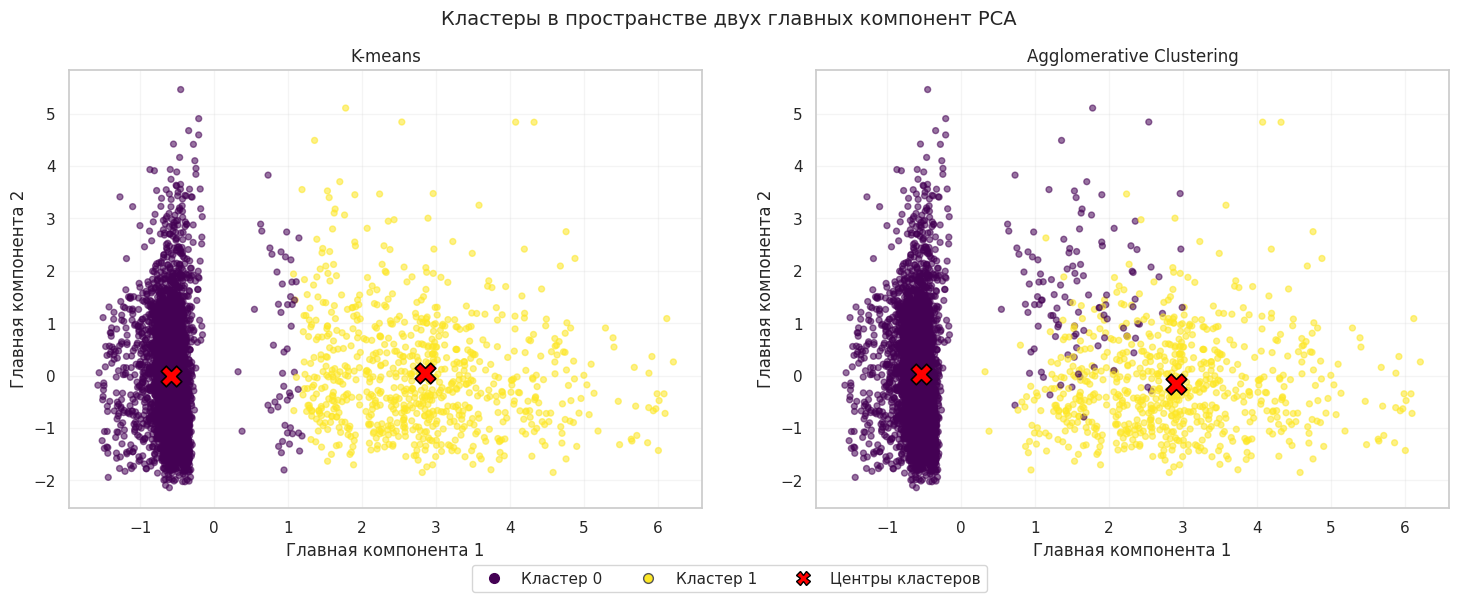

In [22]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
explained_variance_total = explained_variance.sum()

print("Доля объяснённой дисперсии первой компоненты:", round(explained_variance[0], 4))
print("Доля объяснённой дисперсии второй компоненты:", round(explained_variance[1], 4))
print("Суммарная доля объяснённой дисперсии:", round(explained_variance_total, 4))

# Проецируем центры кластеров в то же пространство PCA
kmeans_centers_pca = pca.transform(kmeans_centroids)
agg_centers_pca = pca.transform(agg_centroids)

from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, labels, centers, title in [
    (axes[0], kmeans_labels, kmeans_centers_pca, "K-means"),
    (axes[1], agglomerative_labels, agg_centers_pca, "Agglomerative Clustering")
]:
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        vmin=0,
        vmax=1,
        s=18,
        alpha=0.55
    )
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="X",
        s=220,
        c="red",
        edgecolor="black",
        linewidth=1.2,
        label="Центры кластеров"
    )
    ax.set_title(title)
    ax.set_xlabel("Главная компонента 1")
    ax.set_ylabel("Главная компонента 2")
    ax.grid(alpha=0.2)

legend_handles = [
    Line2D([], [], marker="o", linestyle="None", color="#440154", markersize=7, label="Кластер 0"),
    Line2D([], [], marker="o", linestyle="None", color="#FDE725", markeredgecolor="#555555", markersize=7, label="Кластер 1"),
    Line2D([], [], marker="X", linestyle="None", color="red", markeredgecolor="black", markersize=10, label="Центры кластеров")
]
fig.legend(handles=legend_handles, loc="lower center", ncol=3)
fig.suptitle(
    "Кластеры в пространстве двух главных компонент PCA",
    fontsize=14
)
fig.subplots_adjust(left=0.06, right=0.98, bottom=0.15, top=0.88, wspace=0.18)
plt.show()

#### Вывод по визуализации PCA

На диаграммах отображены результаты кластеризации, выполненной до применения PCA. Красными маркерами `X` обозначены центры кластеров, рассчитанные в исходном стандартизированном пространстве и затем спроецированные в двумерное пространство.

Две главные компоненты сохраняют только часть общей дисперсии данных. Поэтому двумерный график служит наглядной проекцией, но не заменяет расчёт метрик в полном пространстве признаков.

### 8.2. Анализ характеристик полученных кластеров

Для содержательной интерпретации рассмотрим исходные значения признаков. Средние и медианные значения числовых переменных будут рассчитаны по исходному датасету, без стандартизации и ограничения крайних значений. Для категориальных признаков определим наиболее часто встречающуюся категорию и её долю внутри каждого кластера.

In [23]:
# Формируем таблицу с исходными признаками и метками K-means
profile_kmeans = df[selected_features].copy()
profile_kmeans["cluster"] = kmeans_labels

numeric_profile_columns = ["age", "balance", "campaign", "pdays", "previous"]

print("Числовые характеристики кластеров K-means (исходные единицы измерения):")
numeric_cluster_profile = (
    profile_kmeans
    .groupby("cluster")[numeric_profile_columns]
    .agg(["count", "mean", "median"])
    .round(2)
)
display(numeric_cluster_profile)

# Наиболее частые категории и их доли
categorical_profile_rows = []

for cluster_id, group in profile_kmeans.groupby("cluster"):
    for column in categorical_features:
        value_counts = group[column].value_counts(normalize=True)
        categorical_profile_rows.append({
            "Кластер": cluster_id,
            "Признак": column,
            "Наиболее частая категория": value_counts.index[0],
            "Доля категории, %": value_counts.iloc[0] * 100
        })

categorical_cluster_profile = pd.DataFrame(categorical_profile_rows)
display(categorical_cluster_profile.round(2))

# Аналогичный краткий профиль для Agglomerative Clustering
profile_agg = df[selected_features].copy()
profile_agg["cluster"] = agglomerative_labels

print("Числовые характеристики кластеров Agglomerative Clustering (исходные единицы измерения):")
agg_numeric_cluster_profile = (
    profile_agg
    .groupby("cluster")[numeric_profile_columns]
    .agg(["count", "mean", "median"])
    .round(2)
)
display(agg_numeric_cluster_profile)

# Наиболее частые категории и их доли для Agglomerative Clustering
agg_categorical_profile_rows = []
for cluster_id, group in profile_agg.groupby("cluster"):
    for column in categorical_features:
        value_counts = group[column].value_counts(normalize=True)
        agg_categorical_profile_rows.append({
            "Кластер": cluster_id,
            "Признак": column,
            "Наиболее частая категория": value_counts.index[0],
            "Доля категории, %": value_counts.iloc[0] * 100
        })

agg_categorical_cluster_profile = pd.DataFrame(agg_categorical_profile_rows)
display(agg_categorical_cluster_profile.round(2))

Числовые характеристики кластеров K-means (исходные единицы измерения):


age               balance                 campaign              pdays                previous             
        count   mean median   count     mean median    count  mean median count    mean median    count  mean median
cluster                                                                                                             
0        3756  41.13   39.0    3756  1381.27  419.5     3756  2.95    2.0  3756    0.09   -1.0     3756  0.01    0.0
1         765  41.35   39.0     765  1625.84  623.0      765  2.04    1.0   765  234.56  199.0      765  3.13    2.0

,Кластер,Признак,Наиболее частая категория,"Доля категории, %"
0,0,job,management,21.27
1,0,marital,married,62.11
2,0,education,secondary,50.91
3,0,default,no,98.11
4,0,housing,yes,54.69
5,0,loan,no,84.21
6,0,contact,cellular,58.81
7,0,poutcome,unknown,98.64
8,1,job,management,22.22
9,1,marital,married,60.65


Числовые характеристики кластеров Agglomerative Clustering (исходные единицы измерения):


age               balance                 campaign              pdays                previous             
        count   mean median   count     mean median    count  mean median count    mean median    count  mean median
cluster                                                                                                             
0        3817  41.56   40.0    3817  1389.49  425.0     3817  2.93    2.0  3817    2.97   -1.0     3817  0.05    0.0
1         704  39.05   37.0     704  1602.50  597.0      704  2.03    1.0   704  239.30  229.0      704  3.19    2.0

,Кластер,Признак,Наиболее частая категория,"Доля категории, %"
0,0,job,blue-collar,21.04
1,0,marital,married,62.75
2,0,education,secondary,50.88
3,0,default,no,98.14
4,0,housing,yes,53.84
5,0,loan,no,84.39
6,0,contact,cellular,59.05
7,0,poutcome,unknown,97.07
8,1,job,management,24.86
9,1,marital,married,57.10


#### Интерпретация выделенных групп

По результатам K-means выделяются две основные группы клиентов:

- **Кластер 0 — клиенты без зафиксированной предыдущей истории контактов.** Для большинства объектов этого кластера `pdays = -1`, `previous = 0`, а `poutcome = unknown` (98,64%).
- **Кластер 1 — клиенты с предыдущей историей взаимодействия с банком.** Для них характерны положительные значения `pdays` и `previous`; наиболее частое значение `poutcome` — `failure` (61,83%). Доля контактов через `cellular` в этой группе также выше (89,80%).

Agglomerative Clustering выделяет группы с аналогичным смыслом: в одном кластере преобладают клиенты без предыдущей истории контактов, в другом — клиенты с такой историей. Это видно по числовым и категориальным профилям, рассчитанным для обоих методов. Размеры групп немного различаются, но общая структура сохраняется.

Различия по возрасту и балансу выражены слабее, чем различия по истории контактов. По K-means доля клиентов, оформивших депозит, составляет 9,53% в кластере 0 и 21,31% в кластере 1. Это показывает, что у ранее контактировавшей с банком группы доля оформленных депозитов выше, однако такое различие не превращает кластеризацию в задачу прогнозирования.

Следовательно, основное разделение в выбранном наборе признаков связано с тем, взаимодействовал ли клиент с банком в рамках предыдущих кампаний. В K-means все 3705 клиентов без предыдущих контактов попали в кластер 0, а 765 из 816 клиентов с историей контактов — в кластер 1. Столь сильное соответствие объясняется в том числе тем, что отсутствие контактов отражено сразу в `pdays`, `previous` и `poutcome`. Поэтому результат нельзя трактовать как независимое доказательство естественного разделения по финансовым и демографическим характеристикам: это прежде всего сегментация по истории взаимодействия с банком.

## 9. Сравнение двух методов кластеризации

Сравним алгоритмы по внутренним метрикам, размерам групп, внешним метрикам и согласованности разбиений. Для выбора наиболее подходящего результата будем учитывать не только числовые показатели, но и содержательную интерпретацию кластеров.

In [24]:
# Объединяем основные показатели двух алгоритмов в одну таблицу
comparison_rows = []

for method_name, labels, internal_metrics_values, external_metrics_values in [
    ("K-means", kmeans_labels, kmeans_metrics, external_rows[0]),
    (
        "Agglomerative Clustering",
        agglomerative_labels,
        agglomerative_metrics,
        external_rows[1]
    )
]:
    sizes = pd.Series(labels).value_counts().sort_index().to_dict()

    comparison_rows.append({
        "Метод": method_name,
        "Количество кластеров": len(np.unique(labels)),
        "Размеры кластеров": sizes,
        "Silhouette": internal_metrics_values["Silhouette"],
        "Calinski-Harabasz": internal_metrics_values["Calinski-Harabasz"],
        "Davies-Bouldin": internal_metrics_values["Davies-Bouldin"],
        "ARI относительно y": external_metrics_values["ARI"],
        "NMI относительно y": external_metrics_values["NMI"]
    })

final_comparison = pd.DataFrame(comparison_rows).set_index("Метод")
display(final_comparison.round(4))

print(
    "Согласованность кластеров двух методов (ARI):",
    round(adjusted_rand_score(kmeans_labels, agglomerative_labels), 4)
)

,Количество кластеров,Размеры кластеров,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI относительно y,NMI относительно y
Метод,,,,,,,
K-means,2,"{0: 3756, 1: 765}",0.3075,1087.3427,1.5554,0.0969,0.0204
Agglomerative Clustering,2,"{0: 3817, 1: 704}",0.3033,1016.2418,1.5446,0.0790,0.0136


Согласованность кластеров двух методов (ARI): 0.8791


### Вывод по сравнению методов

Оба алгоритма выделили по две группы клиентов и показали близкие значения внутренних метрик. K-means имеет немного более высокий Silhouette Score и Calinski–Harabasz Index, а Agglomerative Clustering — немного более низкий Davies–Bouldin Index. Следовательно, нельзя утверждать, что один метод безусловно превосходит другой по всем критериям.

Согласованность двух разбиений высокая: основная структура групп воспроизводится обоими алгоритмами, хотя границы кластеров и количество объектов в каждой группе немного различаются.

Оба метода выделяют прежде всего клиентов с отсутствующей и присутствующей историей предыдущих контактов. При этом внешние метрики относительно `y` невысоки: полученные кластеры не являются прямым разделением клиентов на оформивших и не оформивших депозит.

Для данного набора данных K-means можно выбрать как основной результат благодаря немного лучшим значениям Silhouette и Calinski–Harabasz, простоте интерпретации центров и высокой устойчивости при повторных запусках. Agglomerative Clustering подтверждает наличие похожей структуры и дополняет анализ дендрограммой.

## 10. Заключение

В ходе лабораторной работы была изучена задача кластеризации и выполнено исследование набора данных Bank Marketing, содержащего сведения о 4521 клиенте банка.

На этапе первичного анализа определены типы признаков, проверены пропуски и дубликаты, исследованы распределения числовых и категориальных переменных, оценена вариативность признаков и выявлены потенциальные выбросы. Для кластеризации была сформирована матрица из демографических, финансовых и поведенческих характеристик. Целевая переменная `y` была исключена из процесса обучения и использована только для внешней оценки.

Числовые признаки стандартизированы с помощью `StandardScaler`, категориальные преобразованы методом One-Hot Encoding. Специальное значение `pdays = -1` обработано как признак отсутствия предыдущего контакта. Крайние значения отдельных числовых переменных ограничены по 1-му и 99-му процентилям без удаления наблюдений.

Были реализованы два алгоритма: K-means и Agglomerative Clustering с методом Ward. Количество кластеров подбиралось с помощью метода локтя, силуэтного анализа и дендрограммы. Для обоих методов наиболее обоснованным оказалось разбиение на две группы.

В результате выделены клиенты без зафиксированной предыдущей истории контактов и клиенты, ранее взаимодействовавшие с банком. Внутренние метрики двух методов оказались близкими, а повторные запуски K-means показали устойчивость результата. Внешние метрики относительно факта оформления депозита невысоки, что указывает на отличие найденной структуры от исходного разделения по `y`.

Таким образом, кластеризация позволила выявить группы клиентов прежде всего по истории маркетингового взаимодействия. Поскольку наличие предыдущего контакта отражено несколькими взаимосвязанными признаками, полученное разделение следует интерпретировать именно в контексте выбранного набора признаков, а не как универсальную сегментацию клиентской базы. K-means выбран в качестве основного метода по совокупности внутренних метрик, устойчивости к случайной инициализации и интерпретируемости, а иерархическая кластеризация подтвердила наличие сходной структуры.

## 11. Список источников

1. UCI Machine Learning Repository. **Bank Marketing**. URL: https://archive.ics.uci.edu/dataset/222/bank+marketing (дата обращения: 03.11.2026).
2. Scikit-learn. **StandardScaler**. URL: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html.
3. Scikit-learn. **KMeans**. URL: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html.
4. Scikit-learn. **AgglomerativeClustering**. URL: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html.
5. Scikit-learn. **Clustering performance evaluation**. URL: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation.
6. Scikit-learn. **PCA**. URL: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html.
7. Теоретические материалы к лабораторной работе. Раздел «Кластеризация», слайды 104–124: задача и условия кластеризации, K-means, иерархическая кластеризация, дендрограмма, метод локтя, силуэтный анализ, внутренние и внешние метрики.
8. SciPy. **Hierarchical clustering (`scipy.cluster.hierarchy`)**. URL: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html.
